# Distinguishing Dangerous Algal Species From Harmless Ones Via Hyperspectral Imagery

**Team Fireflies** · Arab Youth Space Hackathon 2026, Challenge 813 · Water Quality & Inland/Coastal Water Intelligence

This notebook takes NASA PACE OCI Level-2 scenes of the Arabian Gulf and Sea of Oman and labels every dense bloom pixel as *C. polykrikoides*-like (fish-killing red tide), green *Noctiluca*-like (seasonal, non-toxic), diatom-like or unclassified, with a risk tier and a confidence score. It ends by exporting everything the interactive map needs.

**Before you run**
- Mount Google Drive.
- Edit the paths: `PACE_DIR` (1.2), `GEBCO_PATH` (1.6), `REF_DIR` and the reference CSVs (3.4, 3.7), `GEBCO2_PATH` (4.1).
- Run all cells from top to bottom.

**Pipeline**

| Step | What happens |
|---|---|
| 1 | Find the PACE passes, remove flagged pixels, regrid to 0.01°, mask shallow water, classify bloom density |
| 2 | Normalize spectra (430 to 700 nm) and compress them with PCA |
| 3 | Group pixels with two-level k-means, name clusters against 6 reference spectra, apply the label rules |
| 4 | Run the frozen pipeline on the held-out test date (24 March 2025) |
| 5 | Validation checks and summary |
| 6 | Export images, GeoTIFFs, GeoJSON and JSON for the interactive map |

**Dates** (12 PACE passes, October 2024 to March 2026)
- Analysis (training): 30 Oct 2024, 3 Dec 2024, 9 Dec 2024, 23 Jan 2025, 6 Apr 2025, 2 Oct 2025, 16 Nov 2025, 14 Feb 2026, 14 Mar 2026
- Calm (thresholds and false-alarm check): 11 Oct 2024, 25 Oct 2025
- Held-out test: 24 Mar 2025

## Step 1: Load, screen and regrid the PACE passes

### 1.1 Install packages
Installs pyresample (regridding) and netCDF4 (reading the PACE files). Everything else is already in Colab.

In [13]:
# Install and configure
!pip install -q pyresample netCDF4

In [14]:
print([repr(n) for n in os.listdir(os.path.join(PACE_DIR, "analysis"))])

["'raw'", "'preprocessed'", "'pca_model.joblib'", "'kmeans_model.joblib'", "'cluster_naming.csv'"]


### 1.2 Settings and folders
Imports, folder paths and the main settings:
- Study box: 51.2 to 60.79°E, 21.8 to 27.03°N
- Grid: 0.01° (about 1.1 km)
- Depth: water under 5 m is excluded, 5 to 15 m is kept but flagged

**Edit `PACE_DIR`** to point to your PACE folder. Raw files go in `analysis/raw` and `test`; cleaned files are written to the `preprocessed` folders.

In [15]:
# Setup
import os, re, glob
import numpy as np
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pyresample import geometry, kd_tree

PACE_DIR = "/content/drive/MyDrive/HAB Detection Project/Datasets/Satellites/Hyperspectral/PACE"

# raw inputs (each contains AOP / BGC / IOP subfolders)
RAW_DIRS = {
    "analysis": os.path.join(PACE_DIR, "analysis", "raw"),
    "test":     os.path.join(PACE_DIR, "test"),
}
# cleaned outputs (one combined file per pass)
OUT_DIRS = {
    "analysis": os.path.join(PACE_DIR, "analysis", "preprocessed"),
    "test":     os.path.join(PACE_DIR, "test", "preprocessed"),
}

BBOX = (51.2, 21.8, 60.79, 27.03)   # lon_min, lat_min, lon_max, lat_max
RES = 0.01         # grid size in degrees (~1.1 km)
DEPTH_MIN = 5      # excluded below this
DEPTH_FLAG = 15    # 5–15 m kept but flagged as shallow

for d in OUT_DIRS.values():
    os.makedirs(d, exist_ok=True)

### 1.3 Find the PACE files
Scans the raw folders and groups the files by pass timestamp. Each pass needs three Level-2 files: AOP (reflectance, fluorescence, flags), BGC (chlorophyll) and IOP (backscatter). The last line should say `Missing files: none`.

In [16]:
pat = re.compile(r"PACE_OCI\.(\d{8}T\d{6})\.L2\.OC_(AOP|BGC|IOP)")
granules = {}   # timestamp -> {"AOP": path, "BGC": path, "IOP": path}
SOURCE = {}     # timestamp -> "analysis" or "test"

for source, folder in RAW_DIRS.items():
    files = sorted(glob.glob(os.path.join(folder, "**", "*.nc"), recursive=True))
    files = [f for f in files if "preprocessed" not in f]   # skip cleaned outputs
    print(f"{source}: found {len(files)} .nc files")
    for f in files:
        m = pat.search(os.path.basename(f))
        if m:
            ts, kind = m.group(1), m.group(2)
            granules.setdefault(ts, {})[kind] = f
            SOURCE[ts] = source

print(f"\nMatched {len(granules)} passes")
for ts in sorted(granules):
    print(ts, SOURCE[ts], sorted(granules[ts]))

missing = {ts: {"AOP", "BGC", "IOP"} - set(d) for ts, d in granules.items() if len(d) < 3}
print("\nMissing files:", missing if missing else "none")

analysis: found 33 .nc files
test: found 3 .nc files

Matched 12 passes
20241011T091915 analysis ['AOP', 'BGC', 'IOP']
20241030T083958 analysis ['AOP', 'BGC', 'IOP']
20241203T082912 analysis ['AOP', 'BGC', 'IOP']
20241209T083745 analysis ['AOP', 'BGC', 'IOP']
20250123T082632 analysis ['AOP', 'BGC', 'IOP']
20250324T091204 test ['AOP', 'BGC', 'IOP']
20250406T084057 analysis ['AOP', 'BGC', 'IOP']
20251002T085136 analysis ['AOP', 'BGC', 'IOP']
20251025T090903 analysis ['AOP', 'BGC', 'IOP']
20251116T085559 analysis ['AOP', 'BGC', 'IOP']
20260214T084831 analysis ['AOP', 'BGC', 'IOP']
20260314T084316 analysis ['AOP', 'BGC', 'IOP']

Missing files: none


### 1.4 Look inside the files
Prints the groups and variables of one file of each type, to confirm the variable names used below.

In [17]:
# Look inside one file of each type

def show_structure(path):
    with netCDF4.Dataset(path) as nc:
        for gname, g in nc.groups.items():
            print(f"  [{gname}]")
            for vname, v in g.variables.items():
                print(f"      {vname:25s} {v.dimensions} {v.shape}")

ts0 = sorted(granules)[0]
for kind in ["AOP", "BGC", "IOP"]:
    print("=====", kind, "=====")
    show_structure(granules[ts0][kind])

===== AOP =====
  [sensor_band_parameters]
      wavelength                ('wavelength',) (286,)
      fwave                     ('wavelength',) (286,)
      wavelength_3d             ('wavelength_3d',) (172,)
      vcal_gain                 ('number_of_reflective_bands',) (286,)
      vcal_offset               ('number_of_reflective_bands',) (286,)
      F0                        ('number_of_reflective_bands',) (286,)
      aw                        ('number_of_reflective_bands',) (286,)
      bbw                       ('number_of_reflective_bands',) (286,)
      k_oz                      ('number_of_reflective_bands',) (286,)
      k_no2                     ('number_of_reflective_bands',) (286,)
      Tau_r                     ('number_of_reflective_bands',) (286,)
  [scan_line_attributes]
      year                      ('number_of_lines',) (1709,)
      day                       ('number_of_lines',) (1709,)
      msec                      ('number_of_lines',) (1709,)
      time   

### 1.5 Wavelengths and quality flags
Reads the 172 Rrs wavelengths (346 to 719 nm) and the Level-2 flag definitions, then builds one bit mask from the 14 flags we exclude: cloud, land, sun glint, stray light, steep viewing or sun angle, atmospheric correction failures and warnings, and navigation problems. CHLWARN and CHLFAIL are deliberately not excluded, because dense blooms often trigger them.

In [18]:
# Wavelengths and quality flags

with netCDF4.Dataset(granules[ts0]["AOP"]) as nc:
    WL = np.array(nc["sensor_band_parameters"]["wavelength_3d"][:], dtype=np.float32)
    fl = nc["geophysical_data"]["l2_flags"]
    FLAG_NAMES = fl.flag_meanings.split()
    FLAG_MASKS = [int(np.uint32(m)) for m in np.atleast_1d(fl.flag_masks)]

print(f"{len(WL)} bands, {WL.min():.0f}–{WL.max():.0f} nm")

# list of problems we want to exclude (cloud, land, sun glint, atmospheric correction failure..etc)
EXCLUDE = ["ATMFAIL", "LAND", "HIGLINT", "HILT", "HISATZEN", "STRAYLIGHT",
           "CLDICE", "COCCOLITH", "HISOLZEN", "LOWLW", "NAVWARN",
           "MAXAERITER", "ATMWARN", "NAVFAIL"]
BAD_BITS = 0
for name in EXCLUDE:
    if name in FLAG_NAMES:
        BAD_BITS |= FLAG_MASKS[FLAG_NAMES.index(name)]
print("Excluding:", [n for n in EXCLUDE if n in FLAG_NAMES])

172 bands, 346–719 nm
Excluding: ['ATMFAIL', 'LAND', 'HIGLINT', 'HILT', 'HISATZEN', 'STRAYLIGHT', 'CLDICE', 'COCCOLITH', 'HISOLZEN', 'LOWLW', 'NAVWARN', 'MAXAERITER', 'ATMWARN', 'NAVFAIL']


### 1.6 Grid and shallow-water mask
Builds the fixed 0.01° grid and samples GEBCO depth onto it. Water shallower than 5 m is masked, because the seabed shows through and mixes with the water signal. Water between 5 and 15 m is kept but flagged.

**Edit `GEBCO_PATH`** to your GEBCO tile for the study box.

Grid: 523 x 959 pixels
Flagged shallow zone (5–15 m): 3.9% of grid


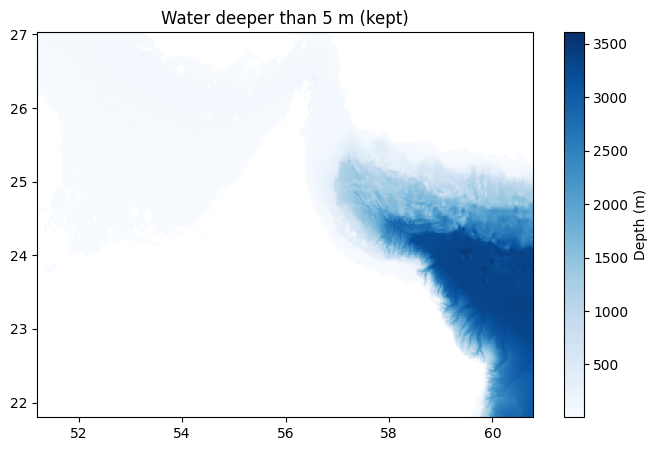

In [19]:
# The grid and the shallow-water mask

lon_min, lat_min, lon_max, lat_max = BBOX
LON1D = np.arange(lon_min + RES/2, lon_max, RES).astype(np.float32)
LAT1D = np.arange(lat_max - RES/2, lat_min, -RES).astype(np.float32)   # north to south
LON2D, LAT2D = np.meshgrid(LON1D, LAT1D)
GRID = geometry.GridDefinition(lons=LON2D, lats=LAT2D)
print("Grid:", LAT1D.size, "x", LON1D.size, "pixels")

GEBCO_PATH = "/content/drive/MyDrive/HAB Detection Project/Datasets/GEBCO bathymetry/gebco_2026_n27.5_s21.3_w50.7_e61.3.nc"
geb = xr.open_dataset(GEBCO_PATH)
elev = geb["elevation"].sel(lat=xr.DataArray(LAT1D, dims="lat"),
                            lon=xr.DataArray(LON1D, dims="lon"),
                            method="nearest").values.astype(np.float32)
DEPTH = -elev                         # positive = water depth in metres
SHALLOW_OR_LAND = DEPTH < DEPTH_MIN   # True where we will mask

SHALLOW_FLAG = (DEPTH >= DEPTH_MIN) & (DEPTH < DEPTH_FLAG)
print(f"Flagged shallow zone (5–15 m): {SHALLOW_FLAG.mean():.1%} of grid")

plt.figure(figsize=(8, 5))
plt.pcolormesh(LON1D, LAT1D, np.where(SHALLOW_OR_LAND, np.nan, DEPTH), cmap="Blues")
plt.colorbar(label="Depth (m)")
plt.title(f"Water deeper than {DEPTH_MIN} m (kept)")
plt.show()

Depth of the water we keep, capped at 100 m so the coastal detail is visible.

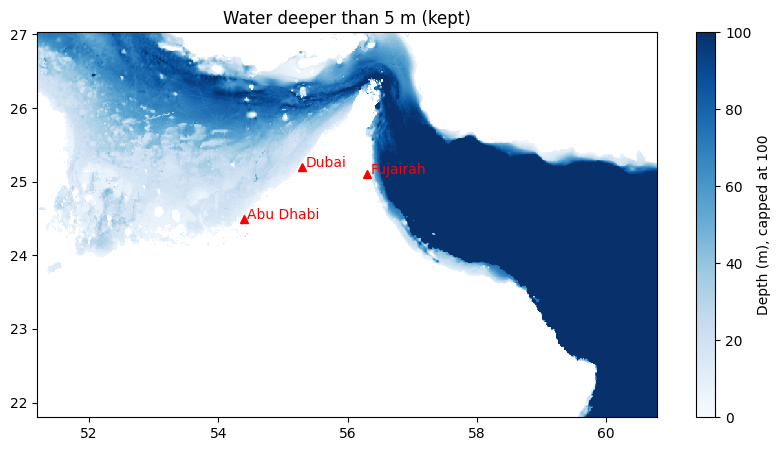

Kept water: 43.0% of the grid


In [20]:
plt.figure(figsize=(10, 5))
plt.pcolormesh(LON1D, LAT1D, np.where(SHALLOW_OR_LAND, np.nan, DEPTH),
               cmap="Blues", vmin=0, vmax=100)
plt.colorbar(label="Depth (m), capped at 100")
for name, lo, la in [("Abu Dhabi", 54.4, 24.5), ("Dubai", 55.3, 25.2), ("Fujairah", 56.3, 25.1)]:
    plt.plot(lo, la, "r^"); plt.text(lo + 0.05, la, name, color="r")
plt.title("Water deeper than 5 m (kept)")
plt.show()

print(f"Kept water: {(~SHALLOW_OR_LAND).mean():.1%} of the grid")

Kept versus excluded water, and the share of water excluded within about 20 km of Abu Dhabi, Dubai and Fujairah. This is the trade-off behind the 5 m cutoff: a 15 m cutoff would remove most of the water near Abu Dhabi.

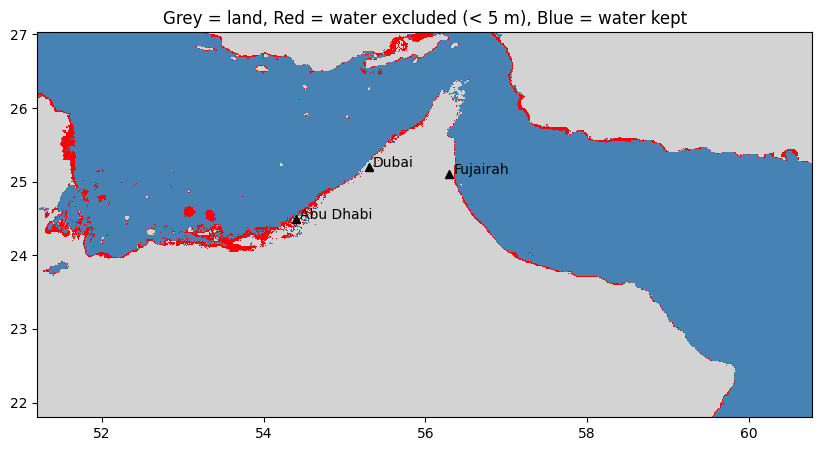

Abu Dhabi: 35% of water within ~20 km is excluded
Dubai: 12% of water within ~20 km is excluded
Fujairah: 10% of water within ~20 km is excluded


In [21]:
from matplotlib.colors import ListedColormap

classes = np.full(DEPTH.shape, 0)          # 0 = land
classes[(DEPTH > 0) & SHALLOW_OR_LAND] = 1  # 1 = water excluded (< 15 m)
classes[~SHALLOW_OR_LAND] = 2               # 2 = water kept

plt.figure(figsize=(10, 5))
plt.pcolormesh(LON1D, LAT1D, classes,
               cmap=ListedColormap(["lightgrey", "red", "steelblue"]), vmin=-0.5, vmax=2.5)
for name, lo, la in [("Abu Dhabi", 54.4, 24.5), ("Dubai", 55.3, 25.2), ("Fujairah", 56.3, 25.1)]:
    plt.plot(lo, la, "k^"); plt.text(lo + 0.05, la, name)
plt.title("Grey = land, Red = water excluded (< 5 m), Blue = water kept")
plt.show()

def excluded_near(lon, lat, km=20):
    r = km / 111
    near = (np.abs(LON2D - lon) < r) & (np.abs(LAT2D - lat) < r) & (DEPTH > 0)
    return (SHALLOW_OR_LAND & near).sum() / max(near.sum(), 1)

for name, lo, la in [("Abu Dhabi", 54.4, 24.5), ("Dubai", 55.3, 25.2), ("Fujairah", 56.3, 25.1)]:
    print(f"{name}: {excluded_near(lo, la):.0%} of water within ~20 km is excluded")

### 1.7 The processing function
`process_granule()` handles one pass:
1. Finds the part of the swath that overlaps the box and reads only that part.
2. Reads Rrs, flags, chlorophyll, nflh and particle backscatter at 560 nm (computed from `bbp_442` and its spectral slope).
3. Keeps pixels with none of the excluded flags and a complete 400 to 700 nm spectrum.
4. Regrids them onto the fixed grid (nearest neighbour, 2 km radius).
5. Applies the shallow-water mask.

Passes with fewer than 500 good pixels are skipped.

In [22]:
# The processing function

def read_var(path, name, sl):
    """Read one variable from geophysical_data (cropped), or return None if absent."""
    with netCDF4.Dataset(path) as nc:
        g = nc["geophysical_data"]
        if name not in g.variables:
            return None
        return np.ma.filled(g[name][sl].astype(np.float32), np.nan)

def find_bbp560(path, sl):
    """Particle backscatter at 560 nm from bbp_442 and its spectral slope."""
    with netCDF4.Dataset(path) as nc:
        names = list(nc["geophysical_data"].variables)
    if "bbp_442" in names and "bbp_s" in names:
        b442 = read_var(path, "bbp_442", sl)
        slope = read_var(path, "bbp_s", sl)
        return b442 * (442.0 / 560.0) ** slope
    print("   bbp_442/bbp_s not found, IOP variables:", names)
    return None

def process_granule(ts):
    p = granules[ts]
    # 1. read navigation and find the rows/cols that touch our box
    with netCDF4.Dataset(p["AOP"]) as nc:
        lat = np.ma.filled(nc["navigation_data"]["latitude"][:].astype(np.float32), np.nan)
        lon = np.ma.filled(nc["navigation_data"]["longitude"][:].astype(np.float32), np.nan)
    buf = 0.05
    inside = ((lon >= lon_min - buf) & (lon <= lon_max + buf) &
              (lat >= lat_min - buf) & (lat <= lat_max + buf))
    if not inside.any():
        print(ts, "does not overlap the box, skipped")
        return None
    rows = np.where(inside.any(axis=1))[0]
    cols = np.where(inside.any(axis=0))[0]
    sl = (slice(rows[0], rows[-1] + 1), slice(cols[0], cols[-1] + 1))
    lat, lon, inside = lat[sl], lon[sl], inside[sl]

    # 2. read only the cropped part of each variable
    rrs = read_var(p["AOP"], "Rrs", sl + (slice(None),))
    with netCDF4.Dataset(p["AOP"]) as nc:
        v = nc["geophysical_data"]["l2_flags"]
        v.set_auto_maskandscale(False)
        flags = np.array(v[sl]).astype(np.uint32)
    chl = read_var(p["BGC"], "chlor_a", sl)
    nflh = read_var(p["AOP"], "nflh", sl)
    if nflh is None:
        nflh = read_var(p["BGC"], "nflh", sl)
    bbp = find_bbp560(p["IOP"], sl)

    # 3. quality mask on the swath
    vis = (WL >= 400) & (WL <= 700)
    good = (inside & np.isfinite(lat) & np.isfinite(lon)
            & ((flags & np.uint32(BAD_BITS)) == 0)
            & np.all(np.isfinite(rrs[..., vis]), axis=2))
    print(f"   {good.sum()} good swath pixels in box")
    if good.sum() < 500:
        print("   too few good pixels (cloud, glint or edge of swath), skipped")
        return None

    # 4. regrid good pixels onto the fixed grid (nearest neighbour, 2 km radius)
    swath = geometry.SwathDefinition(lons=lon[good], lats=lat[good])
    def rs(a):
        return None if a is None else kd_tree.resample_nearest(
            swath, a[good], GRID, radius_of_influence=2000, fill_value=np.nan)
    out = {"Rrs": rs(rrs), "chlor_a": rs(chl), "nflh": rs(nflh), "bbp_560": rs(bbp)}

    # 5. shallow-water / land mask on the grid
    for k, a in out.items():
        if a is not None:
            a[SHALLOW_OR_LAND] = np.nan
    return out

### 1.8 Test on one pass
Runs the function on the first pass and prints the share of valid pixels for each variable.

In [23]:
# Test on one pass first

out = process_granule(ts0)
for k, a in out.items():
    if a is not None:
        print(k, a.shape, f"valid: {np.isfinite(a if a.ndim == 2 else a[..., 0]).mean():.1%}")

   49310 good swath pixels in box
Rrs (523, 959, 172) valid: 17.7%
chlor_a (523, 959) valid: 17.7%
nflh (523, 959) valid: 17.7%
bbp_560 (523, 959) valid: 17.7%


How much of the water we keep does this single pass cover? Cloud, glint and the edge of the swath leave gaps, which is why some passes are much emptier than others.

In [24]:
# the share of usable water that has data

water = ~SHALLOW_OR_LAND
valid = np.isfinite(out["Rrs"][..., 0])
print(f"Usable water in grid: {water.mean():.1%}")
print(f"Of that water, this pass has data for: {valid[water].mean():.1%}")

Usable water in grid: 43.0%
Of that water, this pass has data for: 41.0%


Closes any open NetCDF files, so the next cell can overwrite outputs in Drive without permission errors.

In [25]:
import gc
for obj in list(globals().values()):
    if isinstance(obj, xr.Dataset):
        obj.close()
gc.collect()
print("Closed all open datasets")

Closed all open datasets


### 1.9 Process all passes
Gives each date a role and saves one cleaned file per pass (`<timestamp>_grid.nc`):
- **analysis** (9 dates): used to learn the spectral patterns
- **calm** (11 Oct 2024, 25 Oct 2025): low-bloom dates used to set the fluorescence threshold and to check for false alarms
- **test**: anything in the test folder (24 Mar 2025), never used to fit anything

In [26]:
# Assign roles and process all passes
# Test dates are set automatically from the test folder.

ROLES = {
    "20241030": "analysis", "20241203": "analysis", "20241209": "analysis",
    "20250123": "analysis", "20250406": "analysis", "20251002": "analysis",
    "20251116": "analysis", "20260214": "analysis", "20260314": "analysis",
    "20241011": "calm",
    "20251025": "calm",
}

def save(ts, out, role, out_dir):
    data = {"Rrs": (("lat", "lon", "wavelength"), out["Rrs"])}
    for k in ["chlor_a", "nflh", "bbp_560"]:
        if out[k] is not None:
            data[k] = (("lat", "lon"), out[k])
    data["depth"] = (("lat", "lon"), DEPTH)
    data["shallow_flag"] = (("lat", "lon"), SHALLOW_FLAG.astype(np.int8))
    ds = xr.Dataset(data, coords={"lat": LAT1D, "lon": LON1D, "wavelength": WL},
                    attrs={"timestamp": ts, "role": role})
    path = os.path.join(out_dir, f"{ts}_grid.nc")
    ds.to_netcdf(path, encoding={"Rrs": {"zlib": True, "complevel": 4}})
    return path

for ts in sorted(granules):
    source = SOURCE[ts]
    role = "test" if source == "test" else ROLES.get(ts[:8], "unassigned")
    print(f"{ts} ({role})")
    out = process_granule(ts)
    if out is None:
        continue
    water = ~SHALLOW_OR_LAND
    valid = np.isfinite(out["Rrs"][..., 0])
    path = save(ts, out, role, OUT_DIRS[source])
    print(f"   saved {os.path.basename(path)}, data for {valid[water].mean():.1%} of usable water")

20241011T091915 (calm)
   49310 good swath pixels in box
   saved 20241011T091915_grid.nc, data for 41.0% of usable water
20241030T083958 (analysis)
   108327 good swath pixels in box
   saved 20241030T083958_grid.nc, data for 76.7% of usable water
20241203T082912 (analysis)
   59127 good swath pixels in box
   saved 20241203T082912_grid.nc, data for 52.9% of usable water
20241209T083745 (analysis)
   86143 good swath pixels in box
   saved 20241209T083745_grid.nc, data for 69.1% of usable water
20250123T082632 (analysis)
   46512 good swath pixels in box
   saved 20250123T082632_grid.nc, data for 45.3% of usable water
20250324T091204 (test)
   17990 good swath pixels in box
   saved 20250324T091204_grid.nc, data for 23.0% of usable water
20250406T084057 (analysis)
   102792 good swath pixels in box
   saved 20250406T084057_grid.nc, data for 76.1% of usable water
20251002T085136 (analysis)
   76819 good swath pixels in box
   saved 20251002T085136_grid.nc, data for 59.9% of usable wate

### 1.10 Sanity check: chlorophyll map
Lists every processed pass and maps chlorophyll for one of them, on the same log scale as NASA Worldview. Change the index to look at another date.

0 20241011T091915_grid.nc
1 20241030T083958_grid.nc
2 20241203T082912_grid.nc
3 20241209T083745_grid.nc
4 20250123T082632_grid.nc
5 20250406T084057_grid.nc
6 20251002T085136_grid.nc
7 20251025T090903_grid.nc
8 20251116T085559_grid.nc
9 20260214T084831_grid.nc
10 20260314T084316_grid.nc
11 20250324T091204_grid.nc


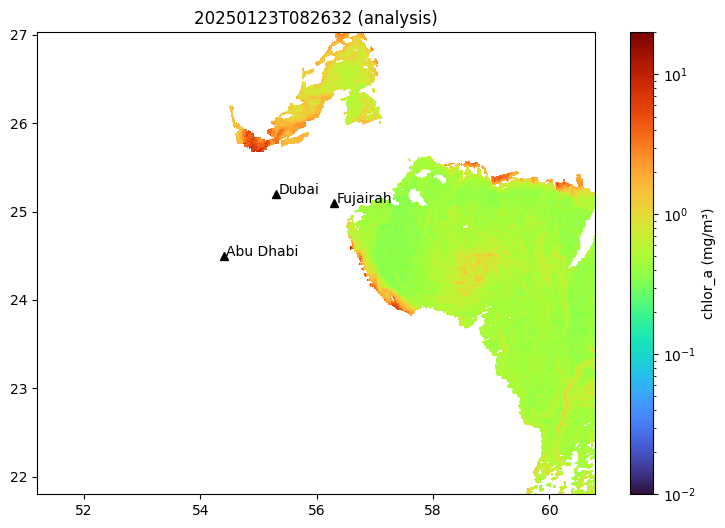

In [27]:
# 1. Does the map looks right?

ALL_GRIDS = sorted(glob.glob(os.path.join(OUT_DIRS["analysis"], "*_grid.nc")) +
                   glob.glob(os.path.join(OUT_DIRS["test"], "*_grid.nc")))
for i, f in enumerate(ALL_GRIDS):
    print(i, os.path.basename(f))

f = ALL_GRIDS[4]   # change the number to check another date
ds = xr.open_dataset(f)

plt.figure(figsize=(9, 6))
plt.pcolormesh(LON1D, LAT1D, ds["chlor_a"], norm=LogNorm(0.01, 20), cmap="turbo")
plt.colorbar(label="chlor_a (mg/m³)")
for name, lo, la in [("Abu Dhabi", 54.4, 24.5), ("Dubai", 55.3, 25.2), ("Fujairah", 56.3, 25.1)]:
    plt.plot(lo, la, "k^"); plt.text(lo + 0.05, la, name)
plt.title(f"{ds.attrs['timestamp']} ({ds.attrs['role']})")
plt.show()

### 1.11 Sanity check: real spectra
Plots three pixels from the same date: the clearest, the most bloom-rich and the shallowest kept. Clear water should peak in the blue, bloom water in the green, and shallow water should be brighter overall. It also prints the share of negative reflectance, which is where we first noticed the blue-band problem in dense blooms (see 3.11).

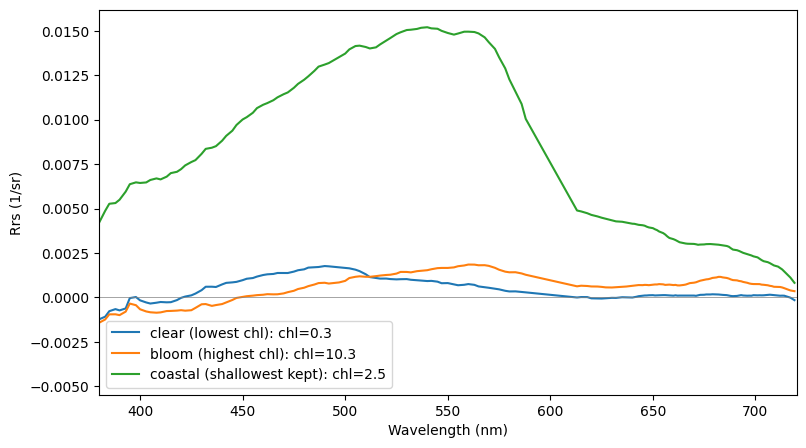

Rrs range (400–700 nm): -0.0021080002 to 0.030948
Share of negative values 400–600 nm: 1.27%


In [28]:
# 2. Look at real spectra

rrs = ds["Rrs"].values
chl = ds["chlor_a"].values
valid = np.isfinite(chl) & np.isfinite(rrs[..., 0])

idx = np.argwhere(valid)
picks = {
    "clear (lowest chl)": idx[np.nanargmin(chl[valid])],
    "bloom (highest chl)": idx[np.nanargmax(chl[valid])],
    "coastal (shallowest kept)": idx[np.nanargmin(DEPTH[valid])],
}

plt.figure(figsize=(9, 5))
for label, (i, j) in picks.items():
    plt.plot(WL, rrs[i, j], label=f"{label}: chl={chl[i, j]:.1f}")
plt.axhline(0, color="grey", lw=0.5)
plt.xlim(380, 720)
plt.xlabel("Wavelength (nm)"); plt.ylabel("Rrs (1/sr)")
plt.legend(); plt.show()

band = (WL >= 400) & (WL <= 600)
print("Rrs range (400–700 nm):", np.nanmin(rrs[..., (WL >= 400) & (WL <= 700)]),
      "to", np.nanmax(rrs[..., (WL >= 400) & (WL <= 700)]))
print("Share of negative values 400–600 nm:", f"{np.mean(rrs[valid][:, band] < 0):.2%}")

### 1.12 Density gate
Each pixel gets a density class:

| Class | Rule |
|---|---|
| 0 No bloom | chlorophyll under 5 mg/m³ |
| 1 Weak bloom | chlorophyll 5 or more, or 10 or more without raised fluorescence |
| 2 Dense bloom | chlorophyll 10 or more **and** raised fluorescence |

"Raised" means nflh above the 95th percentile of normal water (chlorophyll under 1) on the two calm dates, which comes out at 0.2479 W m⁻² µm⁻¹ sr⁻¹. Requiring fluorescence stops muddy water, which inflates the chlorophyll estimate but does not fluoresce, from passing as a dense bloom. Saves `<timestamp>_density.nc`.

In [29]:
CHL_WEAK, CHL_DENSE = 5.0, 10.0

ALL_GRIDS = sorted(glob.glob(os.path.join(OUT_DIRS["analysis"], "*_grid.nc")) +
                   glob.glob(os.path.join(OUT_DIRS["test"], "*_grid.nc")))

# nflh threshold: 95th percentile of nflh in clearly normal water (chl < 1) on calm dates
calm_vals = []
for f in ALL_GRIDS:
    d = xr.open_dataset(f)
    if d.attrs.get("role") == "calm" and "nflh" in d:
        nf, chl = d["nflh"].values, d["chlor_a"].values
        ok = np.isfinite(nf) & np.isfinite(chl) & (chl < 1)
        calm_vals.append(nf[ok])
    d.close()

if calm_vals and sum(len(v) for v in calm_vals) > 0:
    NFLH_THR = float(np.percentile(np.concatenate(calm_vals), 95))
    print(f"nflh threshold (95th pct of normal water on calm dates): {NFLH_THR:.4f}")
else:
    NFLH_THR = None
    print("No calm-date pixels found, so gating on chlorophyll only.")

# density class per pixel: -1 no data, 0 no bloom, 1 weak bloom, 2 dense bloom
for f in ALL_GRIDS:
    d = xr.open_dataset(f)
    chl = d["chlor_a"].values
    dens = np.full(chl.shape, -1, dtype=np.int8)
    ok = np.isfinite(chl)
    dense = ok & (chl >= CHL_DENSE)
    if NFLH_THR is not None and "nflh" in d:
        nf = d["nflh"].values
        dense &= np.isfinite(nf) & (nf > NFLH_THR)
    dens[ok & (chl < CHL_WEAK)] = 0
    dens[ok & (chl >= CHL_WEAK)] = 1
    dens[dense] = 2
    ts, role = d.attrs["timestamp"], d.attrs["role"]
    d.close()
    xr.Dataset({"density_class": (("lat", "lon"), dens)},
               coords={"lat": LAT1D, "lon": LON1D},
               attrs={"timestamp": ts, "role": role,
                      "nflh_thr": NFLH_THR if NFLH_THR is not None else -1}
               ).to_netcdf(f.replace("_grid.nc", "_density.nc"))
    print(f"{ts} ({role}): dense {(dens == 2).sum()} px, weak {(dens == 1).sum()} px")

nflh threshold (95th pct of normal water on calm dates): 0.2479
20241011T091915 (calm): dense 26 px, weak 113 px
20241030T083958 (analysis): dense 4 px, weak 115 px
20241203T082912 (analysis): dense 11 px, weak 116 px
20241209T083745 (analysis): dense 0 px, weak 27 px
20250123T082632 (analysis): dense 7 px, weak 346 px
20250406T084057 (analysis): dense 136 px, weak 1332 px
20251002T085136 (analysis): dense 0 px, weak 137 px
20251025T090903 (calm): dense 0 px, weak 19 px
20251116T085559 (analysis): dense 8 px, weak 106 px
20260214T084831 (analysis): dense 2317 px, weak 9993 px
20260314T084316 (analysis): dense 7048 px, weak 7999 px
20250324T091204 (test): dense 796 px, weak 1899 px


## Step 2: Principal Component Analysis

### 2.1 Prepare the spectra
Uses the 124 bands from 430 to 700 nm and normalizes every spectrum to unit length, so pixels are compared by shape rather than brightness (the same thing the spectral angle measures later). Splits the dates into training (analysis and calm) and test. The test date is never used to fit anything.

In [30]:
# Prepare the spectra

from sklearn.decomposition import PCA
import joblib

# wavelengths used for PCA, k-means and SAM (skip the unreliable violet end)
USE = (WL >= 430) & (WL <= 700)
WL_USE = WL[USE]
print(f"Using {USE.sum()} bands, {WL_USE.min():.0f}–{WL_USE.max():.0f} nm")

def role_of(f):
    with xr.open_dataset(f) as g:
        return g.attrs["role"]

def load_spectra(f):
    """Shape-normalized spectra (430–700 nm), a valid mask and the density class for one date."""
    with xr.open_dataset(f) as g:
        rrs = g["Rrs"].values[..., USE].astype(np.float32)
    with xr.open_dataset(f.replace("_grid.nc", "_density.nc")) as d:
        dens = d["density_class"].values
    norm = np.linalg.norm(rrs, axis=2)
    valid = np.all(np.isfinite(rrs), axis=2) & (norm > 0)
    spec = np.full(rrs.shape, np.nan, dtype=np.float32)
    spec[valid] = rrs[valid] / norm[valid][:, None]
    return spec, valid, dens

# refresh the file list (after the deletions)
ALL_GRIDS = sorted(glob.glob(os.path.join(OUT_DIRS["analysis"], "*_grid.nc")) +
                   glob.glob(os.path.join(OUT_DIRS["test"], "*_grid.nc")))
TRAIN_FILES = [f for f in ALL_GRIDS if role_of(f) in ("analysis", "calm")]
TEST_FILES = [f for f in ALL_GRIDS if role_of(f) == "test"]
print(f"{len(TRAIN_FILES)} training dates, {len(TEST_FILES)} test date(s)")

Using 124 bands, 430–699 nm
11 training dates, 1 test date(s)


### 2.2 Pick training pixels and fit PCA
Blooms are rare, so a random sample would barely contain them. From each training date we take up to 30,000 bloom pixels (weak or dense) and up to 30,000 others, 359,860 pixels in total.

PCA keeps the smallest number of components that explain 99% of the variance, between 5 and 10. Here that is 5 components, explaining 99.24%. The fitted model is saved, so every date is transformed with exactly the same model.

In [31]:
# Pick training pixels and fit PCA

rng = np.random.default_rng(0)
PER_DATE = 30000   # max pixels per group per date

samples = []
for f in TRAIN_FILES:
    spec, valid, dens = load_spectra(f)
    X, dv = spec[valid], dens[valid]
    bloom_idx = np.where(dv >= 1)[0]     # weak + dense bloom pixels
    other_idx = np.where(dv < 1)[0]      # everything else
    if len(bloom_idx) > PER_DATE:
        bloom_idx = rng.choice(bloom_idx, PER_DATE, replace=False)
    if len(other_idx) > PER_DATE:
        other_idx = rng.choice(other_idx, PER_DATE, replace=False)
    samples.append(X[np.concatenate([bloom_idx, other_idx])])
    print(f"{os.path.basename(f)[:15]}: {len(bloom_idx)} bloom + {len(other_idx)} other pixels")

X_train = np.concatenate(samples)
print(f"\nTraining pixels: {len(X_train):,}")

pca_full = PCA(n_components=20, random_state=0).fit(X_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)
N_PC = int(np.searchsorted(cum, 0.99) + 1)
N_PC = min(max(N_PC, 5), 10)            # keep between 5 and 10 components
pca = PCA(n_components=N_PC, random_state=0).fit(X_train)
print(f"Keeping {N_PC} components, explaining {cum[N_PC - 1]:.2%} of the variance")

joblib.dump({"pca": pca, "use_mask": USE, "wl_use": WL_USE},
            os.path.join(PACE_DIR, "analysis", "pca_model.joblib"))

20241011T091915: 139 bloom + 30000 other pixels
20241030T083958: 119 bloom + 30000 other pixels
20241203T082912: 127 bloom + 30000 other pixels
20241209T083745: 27 bloom + 30000 other pixels
20250123T082632: 353 bloom + 30000 other pixels
20250406T084057: 1468 bloom + 30000 other pixels
20251002T085136: 137 bloom + 30000 other pixels
20251025T090903: 19 bloom + 30000 other pixels
20251116T085559: 114 bloom + 30000 other pixels
20260214T084831: 12310 bloom + 30000 other pixels
20260314T084316: 15047 bloom + 30000 other pixels

Training pixels: 359,860
Keeping 5 components, explaining 99.24% of the variance


['/content/drive/MyDrive/HAB Detection Project/Datasets/Satellites/Hyperspectral/PACE/analysis/pca_model.joblib']

### 2.3 Variance chart
Left: the variance explained by each component and the running total. Right: the wavelength weights of the first four components, which show where each one "looks". PC1 explains about 79% and contrasts blue against green reflectance, which is what separates bloom water from clear water. Saved as `export/pca_variance.png`.

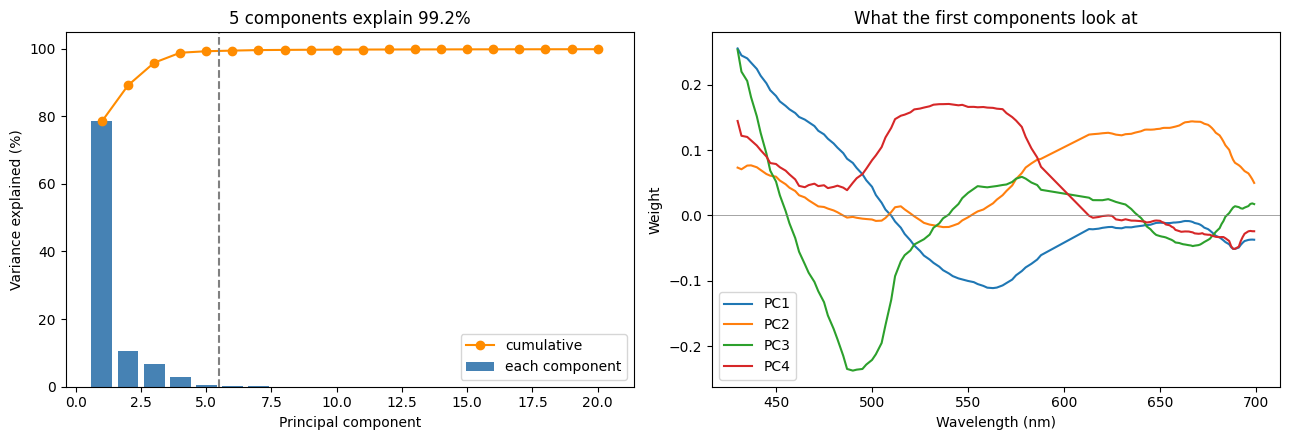

In [32]:
# The variance chart, and what each component means

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

n = np.arange(1, 21)
ax[0].bar(n, pca_full.explained_variance_ratio_ * 100, color="steelblue", label="each component")
ax[0].plot(n, cum * 100, "o-", color="darkorange", label="cumulative")
ax[0].axvline(N_PC + 0.5, color="grey", ls="--")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Variance explained (%)")
ax[0].set_title(f"{N_PC} components explain {cum[N_PC - 1]:.1%}")
ax[0].legend()

for k in range(min(4, N_PC)):
    ax[1].plot(WL_USE, pca.components_[k], label=f"PC{k + 1}")
ax[1].axhline(0, color="grey", lw=0.5)
ax[1].set_xlabel("Wavelength (nm)"); ax[1].set_ylabel("Weight")
ax[1].set_title("What the first components look at")
ax[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(PACE_DIR, "export", "pca_variance.png"), dpi=150)
plt.show()

### 2.4 Transform every date
Applies the frozen PCA to every date, test included, and saves `<timestamp>_pca.nc`.

In [33]:
# Transform every date with the frozen PCA

for f in ALL_GRIDS:
    spec, valid, dens = load_spectra(f)
    pcs = np.full(valid.shape + (N_PC,), np.nan, dtype=np.float32)
    pcs[valid] = pca.transform(spec[valid])
    out = f.replace("_grid.nc", "_pca.nc")
    xr.Dataset({"pc": (("lat", "lon", "component"), pcs)},
               coords={"lat": LAT1D, "lon": LON1D, "component": np.arange(1, N_PC + 1)},
               attrs={"timestamp": os.path.basename(f)[:15], "role": role_of(f)}
               ).to_netcdf(out)
    print(f"{os.path.basename(out)}: {valid.sum():,} pixels transformed")

20241011T091915_pca.nc: 88,592 pixels transformed
20241030T083958_pca.nc: 165,472 pixels transformed
20241203T082912_pca.nc: 114,281 pixels transformed
20241209T083745_pca.nc: 149,194 pixels transformed
20250123T082632_pca.nc: 97,757 pixels transformed
20250406T084057_pca.nc: 164,187 pixels transformed
20251002T085136_pca.nc: 129,234 pixels transformed
20251025T090903_pca.nc: 95,149 pixels transformed
20251116T085559_pca.nc: 125,874 pixels transformed
20260214T084831_pca.nc: 200,192 pixels transformed
20260314T084316_pca.nc: 113,043 pixels transformed
20250324T091204_pca.nc: 49,625 pixels transformed


### 2.5 Visual check
Maps PC1 and PC2 on 14 March 2026, our densest bloom date. They should show real structure, such as bloom swirls and coastal zones, not random speckle.

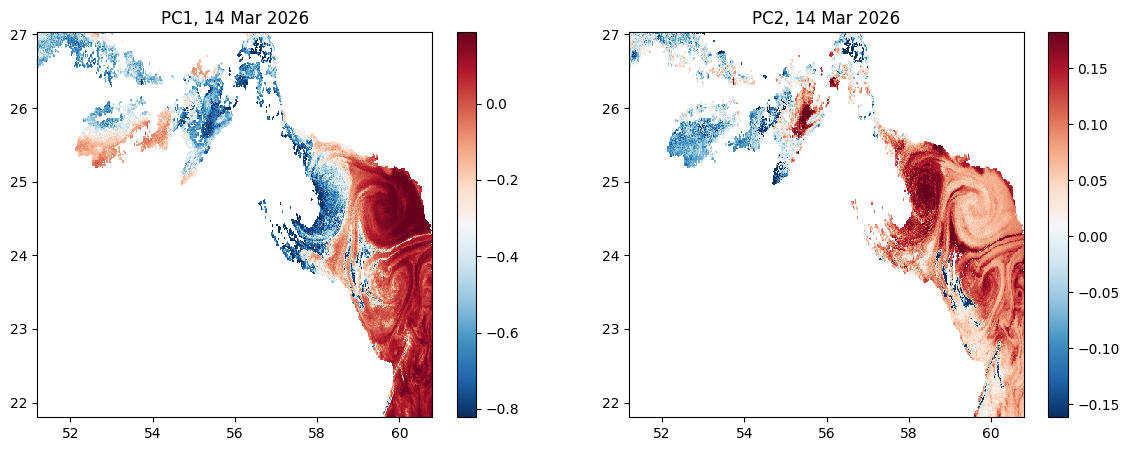

In [34]:
# Quick visual check

f = [g for g in ALL_GRIDS if "20260314" in g][0]   # our densest bloom date
with xr.open_dataset(f.replace("_grid.nc", "_pca.nc")) as p:
    pcs = p["pc"].values

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k in range(2):
    im = ax[k].pcolormesh(LON1D, LAT1D, pcs[..., k], cmap="RdBu_r",
                          vmin=np.nanpercentile(pcs[..., k], 2), vmax=np.nanpercentile(pcs[..., k], 98))
    ax[k].set_title(f"PC{k + 1}, 14 Mar 2026"); plt.colorbar(im, ax=ax[k])
plt.show()

Chlorophyll, density class and PC1 side by side for 14 March 2026, plus the mean PC1 per density class. Dense bloom pixels have a much lower PC1 (about −0.76) than non-bloom water (about −0.14), so PC1 tracks green-peaked bloom water.

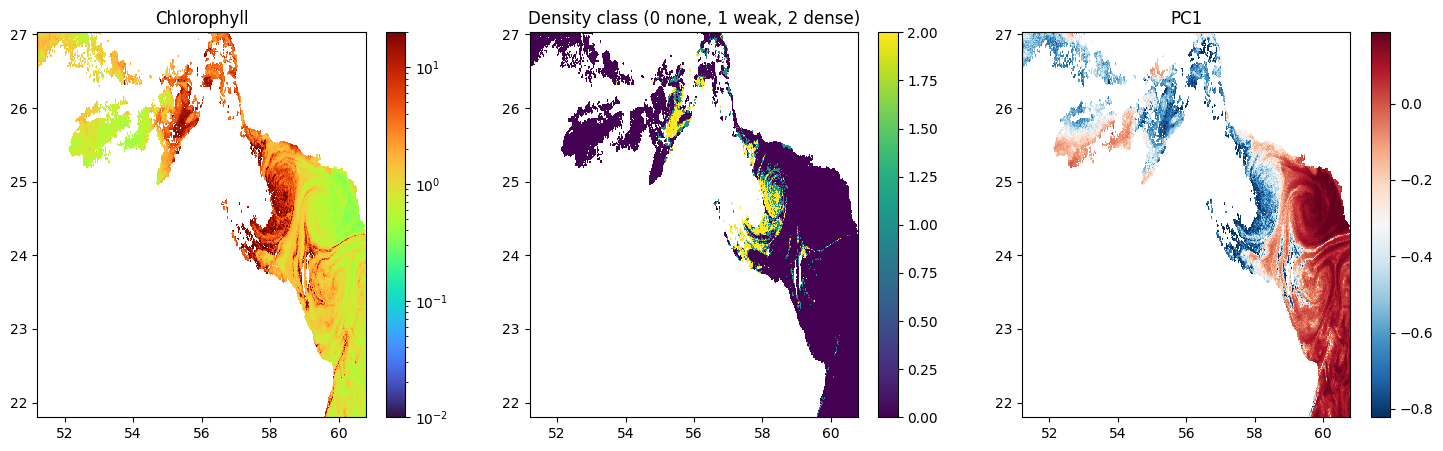

dense bloom : mean PC1 = -0.755  (7048 px)
weak bloom  : mean PC1 = -0.615  (7999 px)
no bloom    : mean PC1 = -0.142  (97512 px)


In [35]:
f = [g for g in ALL_GRIDS if "20260314" in g][0]
with xr.open_dataset(f) as g:
    chl = g["chlor_a"].values
with xr.open_dataset(f.replace("_grid.nc", "_density.nc")) as d:
    dens = d["density_class"].values
with xr.open_dataset(f.replace("_grid.nc", "_pca.nc")) as p:
    pc1 = p["pc"].values[..., 0]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
im0 = ax[0].pcolormesh(LON1D, LAT1D, chl, norm=LogNorm(0.01, 20), cmap="turbo")
ax[0].set_title("Chlorophyll"); plt.colorbar(im0, ax=ax[0])
im1 = ax[1].pcolormesh(LON1D, LAT1D, np.where(dens >= 0, dens, np.nan), cmap="viridis", vmin=0, vmax=2)
ax[1].set_title("Density class (0 none, 1 weak, 2 dense)"); plt.colorbar(im1, ax=ax[1])
im2 = ax[2].pcolormesh(LON1D, LAT1D, pc1, cmap="RdBu_r",
                       vmin=np.nanpercentile(pc1, 2), vmax=np.nanpercentile(pc1, 98))
ax[2].set_title("PC1"); plt.colorbar(im2, ax=ax[2])
plt.show()

for name, mask in [("dense bloom", dens == 2), ("weak bloom", dens == 1), ("no bloom", dens == 0)]:
    print(f"{name:12s}: mean PC1 = {np.nanmean(pc1[mask]):+.3f}  ({mask.sum()} px)")

## Step 3: Clustering and species naming

### 3.1 Two-level k-means
- **Level 1:** splits the training pixels into 6 broad water types using the PCA components as they are, so PC1 drives the split.
- **Level 2:** splits each broad type into 5 sub-types after standardizing the components, so the smaller components, where pigment detail lives, get an equal say.

That gives 30 clusters (cluster id = coarse × 5 + fine). Both levels are saved and never refitted.

In [36]:
# two level k means

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

N_COARSE, N_FINE = 6, 5
N_CLUSTERS = N_COARSE * N_FINE

Z_train = pca.transform(X_train)          # the same training pixels PCA was fitted on

# level 1: broad water types (on raw PCs, so PC1's big differences drive it)
coarse_km = KMeans(n_clusters=N_COARSE, n_init=10, random_state=0).fit(Z_train)
coarse_lab = coarse_km.labels_

# level 2: sub-types inside each coarse group (on standardized PCs,
# so the small components, where pigment detail lives, get an equal say)
fine_models = {}
for c in range(N_COARSE):
    Zc = Z_train[coarse_lab == c]
    k = min(N_FINE, max(1, len(Zc) // 200))
    scaler = StandardScaler().fit(Zc)
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(scaler.transform(Zc))
    fine_models[c] = (scaler, km)
    print(f"coarse group {c}: {len(Zc):,} training px -> {k} fine clusters")

def cluster_id(c, f):
    return c * N_FINE + f

joblib.dump({"coarse": coarse_km, "fine": fine_models, "n_fine": N_FINE},
            os.path.join(PACE_DIR, "analysis", "kmeans_model.joblib"))

coarse group 0: 107,024 training px -> 5 fine clusters
coarse group 1: 7,331 training px -> 5 fine clusters
coarse group 2: 25,244 training px -> 5 fine clusters
coarse group 3: 81,699 training px -> 5 fine clusters
coarse group 4: 19,565 training px -> 5 fine clusters
coarse group 5: 118,997 training px -> 5 fine clusters


['/content/drive/MyDrive/HAB Detection Project/Datasets/Satellites/Hyperspectral/PACE/analysis/kmeans_model.joblib']

### 3.2 Assign every pixel to a cluster
Runs every valid pixel of every date, test included, through the frozen models and saves `<timestamp>_clusters.nc` (cluster 0 to 29, or −1 for no data).

In [37]:
# Assign every pixel of every date to a cluster

def assign_clusters(pcs_flat):
    coarse = coarse_km.predict(pcs_flat)
    out = np.empty(len(pcs_flat), dtype=np.int16)
    for c, (scaler, km) in fine_models.items():
        m = coarse == c
        if m.any():
            out[m] = cluster_id(c, km.predict(scaler.transform(pcs_flat[m])))
    return out

for f in ALL_GRIDS:
    with xr.open_dataset(f.replace("_grid.nc", "_pca.nc")) as p:
        pcs = p["pc"].values
    valid = np.all(np.isfinite(pcs), axis=2)
    cl = np.full(valid.shape, -1, dtype=np.int16)
    cl[valid] = assign_clusters(pcs[valid])
    xr.Dataset({"cluster": (("lat", "lon"), cl)},
               coords={"lat": LAT1D, "lon": LON1D}).to_netcdf(f.replace("_grid.nc", "_clusters.nc"))
    print(f"{os.path.basename(f)[:15]} ({role_of(f)}): {valid.sum():,} px assigned, "
          f"{len(np.unique(cl[valid]))} clusters used")

20241011T091915 (calm): 88,592 px assigned, 20 clusters used
20241030T083958 (analysis): 165,472 px assigned, 18 clusters used
20241203T082912 (analysis): 114,281 px assigned, 21 clusters used
20241209T083745 (analysis): 149,194 px assigned, 22 clusters used
20250123T082632 (analysis): 97,757 px assigned, 22 clusters used
20250406T084057 (analysis): 164,187 px assigned, 29 clusters used
20251002T085136 (analysis): 129,234 px assigned, 23 clusters used
20251025T090903 (calm): 95,149 px assigned, 15 clusters used
20251116T085559 (analysis): 125,874 px assigned, 23 clusters used
20260214T084831 (analysis): 200,192 px assigned, 28 clusters used
20260314T084316 (analysis): 113,043 px assigned, 27 clusters used
20250324T091204 (test): 49,625 px assigned, 26 clusters used


### 3.3 Average spectrum per cluster
Averages the normalized spectra of each cluster over the training dates only, and records its size, share of dense pixels and mean chlorophyll. Clusters with at least 50 dense pixels are named from their dense pixels only, so a bloom signal is not diluted by the surrounding water.

The plot shows the 6 most bloom-rich clusters: low blue, a green peak and a fluorescence bump near 685 nm. Values below about 490 nm go negative, which is over-correction by the atmospheric correction inside dense blooms (see 3.11).

Clusters named from their dense pixels only: [np.int64(5), np.int64(9), np.int64(12), np.int64(13), np.int64(14), np.int64(20), np.int64(21), np.int64(22), np.int64(24)]
cluster    pixels  dense %  mean chl
      0    75,434     0.0%      0.24
      1   130,633     0.0%      0.47
      2    58,185     0.0%      0.44
      3    79,281     0.0%      0.46
      4    80,517     0.0%      0.28
      5     1,789    27.5%     22.52
      6     1,137     0.0%     47.52
      7     1,981     0.7%      9.32
      8     1,236     0.3%     13.57
      9     2,253     8.0%     49.53
     10    27,427     0.0%      2.34
     11    14,224     0.0%      1.10
     12    10,149     4.8%      4.77
     13     5,604     3.5%      5.14
     14    22,725     0.3%      3.03
     15    83,924     0.0%      1.49
     16   112,488     0.0%      1.08
     17    62,422     0.0%      1.86
     18    51,211     0.0%      0.83
     19    74,674     0.0%      1.76
     20     7,810    70.9%     14.96
     21     6,51

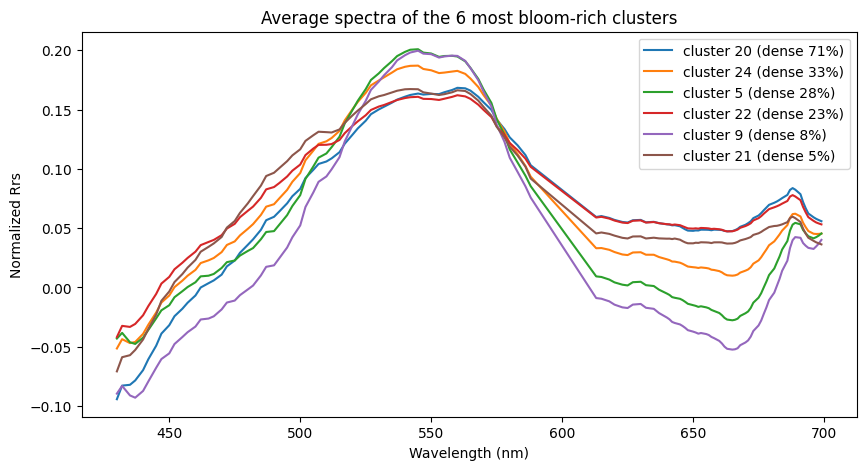

In [38]:
# Average spectrum per cluster

sum_spec = np.zeros((N_CLUSTERS, USE.sum()))
n_px = np.zeros(N_CLUSTERS)
n_dense = np.zeros(N_CLUSTERS)
sum_chl = np.zeros(N_CLUSTERS)
n_chl = np.zeros(N_CLUSTERS)

sum_spec_dense = np.zeros((N_CLUSTERS, USE.sum()))

for f in TRAIN_FILES:                      # training dates only, so the test date can't influence naming
    spec, valid, dens = load_spectra(f)
    with xr.open_dataset(f.replace("_grid.nc", "_clusters.nc")) as c:
        cl = c["cluster"].values
    with xr.open_dataset(f) as g:
        chl = g["chlor_a"].values
    m = valid & (cl >= 0)
    ids, S = cl[m], spec[m]
    for k in np.unique(ids):
        sum_spec[k] += S[ids == k].sum(axis=0)
    n_px += np.bincount(ids, minlength=N_CLUSTERS)
    n_dense += np.bincount(ids, weights=(dens[m] == 2).astype(float), minlength=N_CLUSTERS)
    md = m & (dens == 2)
    ids_d, S_d = cl[md], spec[md]
    for k in np.unique(ids_d):
        sum_spec_dense[k] += S_d[ids_d == k].sum(axis=0)
    ok = np.isfinite(chl[m])
    sum_chl += np.bincount(ids[ok], weights=chl[m][ok], minlength=N_CLUSTERS)
    n_chl += np.bincount(ids[ok], minlength=N_CLUSTERS)

with np.errstate(invalid="ignore", divide="ignore"):
    avg_spec = sum_spec / n_px[:, None]
    avg_spec /= np.linalg.norm(avg_spec, axis=1, keepdims=True)   # back to unit length
    mean_chl = sum_chl / n_chl
    dense_share = n_dense / n_px

MIN_DENSE_PX = 50   # need at least this many dense pixels to characterize a cluster's bloom
with np.errstate(invalid="ignore", divide="ignore"):
    avg_spec_dense = sum_spec_dense / n_dense[:, None]
    avg_spec_dense /= np.linalg.norm(avg_spec_dense, axis=1, keepdims=True)
use_dense = n_dense >= MIN_DENSE_PX
naming_spec = np.where(use_dense[:, None], avg_spec_dense, avg_spec)
print("Clusters named from their dense pixels only:", list(np.where(use_dense)[0]))

print(f"{'cluster':>7s} {'pixels':>9s} {'dense %':>8s} {'mean chl':>9s}")
for k in range(N_CLUSTERS):
    if n_px[k] > 0:
        print(f"{k:7d} {int(n_px[k]):9,d} {dense_share[k]:8.1%} {mean_chl[k]:9.2f}")

plt.figure(figsize=(10, 5))
top = np.argsort(-dense_share)[:6]
for k in top:
    plt.plot(WL_USE, avg_spec[k], label=f"cluster {k} (dense {dense_share[k]:.0%})")
plt.xlabel("Wavelength (nm)"); plt.ylabel("Normalized Rrs")
plt.title("Average spectra of the 6 most bloom-rich clusters"); plt.legend(); plt.show()

### 3.4 Build the reference library
Six references, all normalized to unit length:
- **Species**, digitized from published figures and resampled to the PACE bands: *C. polykrikoides* (Kim, Yoo and Son 2016, Korea), green *Noctiluca* and diatom (Dwivedi et al. 2015, northern Arabian Sea). Each is used only where its figure has data.
- **Water types**, built from our own training scenes: clear water (chlorophyll under 0.3, deeper than 50 m), turbid water (top 5% particle backscatter, 15 m or deeper, not dense) and shallow seabed (brightest 10% at 555 nm in the 5 to 15 m zone).

The water types act as decoys, so a cluster that is really just water is not forced into a species name.

**Edit `REF_DIR` and the CSV paths.**

C. polykrikoides: covers 430–699 nm
Green Noctiluca: covers 430–699 nm
Diatom: covers 430–699 nm
Clear water: built from 20,294 pixels
Turbid water: built from 53,216 pixels
Shallow seabed: built from 7,229 pixels


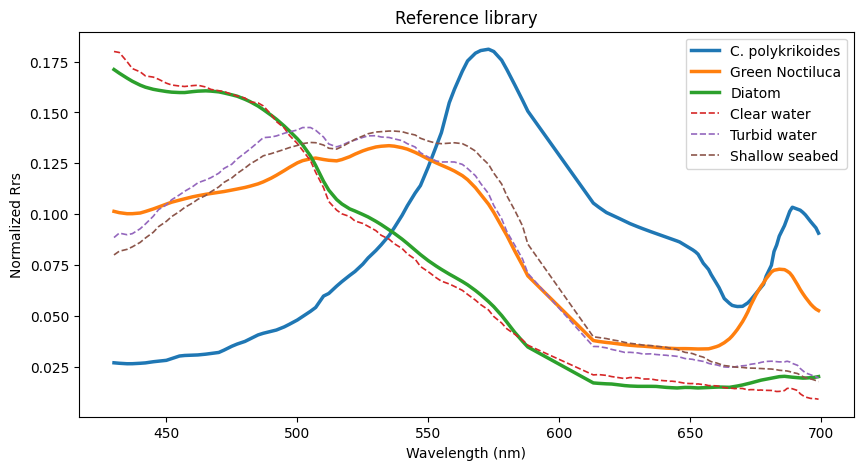

In [39]:
# Build the 6 references

REF_DIR = "/content/drive/MyDrive/HAB Detection Project/Datasets/References"
REF_CSV = {
    "C. polykrikoides": ("/content/drive/MyDrive/HAB Detection Project/Datasets/References/Cochlodinium Polykrikoides.csv",       "Kim, Yoo & Son 2016 (digitized)", "Korea"),
    "Green Noctiluca":  ("/content/drive/MyDrive/HAB Detection Project/Datasets/References/Green Noctiluca.csv", "Dwivedi et al. 2015 (digitized)", "Northern Arabian Sea"),
    "Diatom":           ("/content/drive/MyDrive/HAB Detection Project/Datasets/References/Diatom.csv",    "Dwivedi et al. 2015 (digitized)", "Northern Arabian Sea"),
}

def unit(v):
    n = np.linalg.norm(v)
    return v / n if n > 0 else v

def load_digitized(path):
    data = np.genfromtxt(path, delimiter=",", invalid_raise=False)
    data = data[np.all(np.isfinite(data), axis=1)]
    data = data[np.argsort(data[:, 0])]
    wl, val = data[:, 0], data[:, 1]
    mask = (WL_USE >= wl.min()) & (WL_USE <= wl.max())   # only where the figure has data
    curve = np.full(WL_USE.shape, np.nan)
    curve[mask] = np.interp(WL_USE[mask], wl, val)        # resample to PACE bands
    curve[mask] = unit(curve[mask])
    return curve, mask

REFS = {}
for name, (fname, source, region) in REF_CSV.items():
    curve, mask = load_digitized(os.path.join(REF_DIR, fname))
    REFS[name] = {"curve": curve, "mask": mask, "kind": "species", "source": source, "region": region}
    print(f"{name}: covers {WL_USE[mask].min():.0f}–{WL_USE[mask].max():.0f} nm")

# water-type decoys, taken from our own training dates
I555 = int(np.argmin(np.abs(WL - 555)))
picked = {"Clear water": [], "Turbid water": [], "Shallow seabed": []}
rng_ref = np.random.default_rng(1)

for f in TRAIN_FILES:
    spec, valid, dens = load_spectra(f)
    with xr.open_dataset(f) as g:
        chl = g["chlor_a"].values
        bbp = g["bbp_560"].values if "bbp_560" in g else np.full(chl.shape, np.nan)
        r555 = g["Rrs"].isel(wavelength=I555).values
    base = valid & np.isfinite(chl)

    clear = base & (chl < 0.3) & (DEPTH > 50) & (dens == 0)
    deepish = base & (DEPTH >= 15) & (dens != 2) & (chl < 10) & np.isfinite(bbp)
    turbid = deepish & (bbp >= np.nanpercentile(bbp[deepish], 95)) if deepish.any() else deepish
    shallow = base & SHALLOW_FLAG & (dens != 2) & (chl < 5)
    seabed = shallow & (r555 >= np.nanpercentile(r555[shallow], 90)) if shallow.any() else shallow

    for name, sel in [("Clear water", clear), ("Turbid water", turbid), ("Shallow seabed", seabed)]:
        S = spec[sel]
        if len(S) > 5000:
            S = S[rng_ref.choice(len(S), 5000, replace=False)]
        picked[name].append(S)

sources = {"Clear water": "offshore pixels, chl < 0.3, depth > 50 m",
           "Turbid water": "top 5% particle backscatter, depth >= 15 m, not dense",
           "Shallow seabed": "brightest 10% at 555 nm in the 5–15 m zone, chl < 5"}
for name, parts in picked.items():
    S = np.concatenate(parts)
    REFS[name] = {"curve": unit(S.mean(axis=0)), "mask": np.ones(len(WL_USE), bool),
                  "kind": "water", "source": f"Own PACE scenes: {sources[name]}", "region": "Study area"}
    print(f"{name}: built from {len(S):,} pixels")

plt.figure(figsize=(10, 5))
for name, r in REFS.items():
    plt.plot(WL_USE, r["curve"], label=name, lw=2.5 if r["kind"] == "species" else 1.2,
             ls="-" if r["kind"] == "species" else "--")
plt.xlabel("Wavelength (nm)"); plt.ylabel("Normalized Rrs"); plt.title("Reference library")
plt.legend(); plt.show()

### 3.5 Name each cluster
For each cluster:
1. **Spectral angle (SAM)** between the cluster spectrum and each reference over 500 to 700 nm. A smaller angle means a more similar shape.
2. **Second-derivative angle:** the same comparison on Savitzky-Golay second derivatives (11 bands, cubic), which highlight narrow pigment features.
3. **Confidence** = (angle to runner-up − angle to best) ÷ angle between those two references, clipped to 0 to 1.

A species name is given only if the confidence is 0.25 or more **and** the derivative comparison picks the same reference. Otherwise the cluster stays unclassified. The table is saved as `cluster_naming.csv`.

In [40]:
# Naming with SAM, the second derivative and the margin rule

from scipy.signal import savgol_filter
import pandas as pd

SG_WIN, SG_POLY = 11, 3        # smoothing window: 11 bands (~24 nm), cubic fit
MARGIN_MIN = 0.25              # below this, "too close to call"
REQUIRE_DERIV_AGREE = True     # species name only if both comparisons agree
COMPARE_MIN = 500              # main comparison starts here (bands below are over-corrected in dense blooms)
CMP = WL_USE >= COMPARE_MIN

def sam_deg(a, b, mask):
    a, b = unit(a[mask]), unit(b[mask])
    return float(np.degrees(np.arccos(np.clip(np.dot(a, b), -1, 1))))

def second_deriv(curve, mask):
    out = np.full(curve.shape, np.nan)
    idx = np.where(mask)[0]
    m2 = np.zeros(curve.shape, bool)
    if len(idx) > SG_WIN:
        out[idx] = savgol_filter(curve[idx], SG_WIN, SG_POLY, deriv=2)
        m2[idx[SG_WIN // 2: len(idx) - SG_WIN // 2]] = True    # drop unreliable edges
    return out, m2

for r in REFS.values():
    r["d2"], r["d2mask"] = second_deriv(r["curve"], r["mask"])

ref_names = list(REFS)
rows = []
for k in range(N_CLUSTERS):
    if n_px[k] == 0 or not np.all(np.isfinite(naming_spec[k])):
        continue
    cd2, cd2m = second_deriv(naming_spec[k], np.ones(len(WL_USE), bool))
    main = {n: sam_deg(naming_spec[k], REFS[n]["curve"], REFS[n]["mask"] & CMP) for n in ref_names}
    deriv = {n: sam_deg(cd2, REFS[n]["d2"], REFS[n]["d2mask"] & cd2m) for n in ref_names}

    order = sorted(main, key=main.get)
    best, second = order[0], order[1]
    common = REFS[best]["mask"] & REFS[second]["mask"] & CMP
    pair = sam_deg(REFS[best]["curve"], REFS[second]["curve"], common)
    conf = float(np.clip((main[second] - main[best]) / pair, 0, 1)) if pair > 0 else 0.0
    d2_best = min(deriv, key=deriv.get)

    named = conf >= MARGIN_MIN and (d2_best == best or not REQUIRE_DERIV_AGREE)
    rows.append({"cluster": k, "pixels": int(n_px[k]), "dense_%": round(100 * dense_share[k], 1),
                 "best": best, "angle_best": round(main[best], 2),
                 "runner_up": second, "angle_2nd": round(main[second], 2),
                 "ref_gap": round(pair, 2), "confidence": round(conf, 2),
                 "deriv_best": d2_best, "named": named,
                 "best_is_water": REFS[best]["kind"] == "water",
                 "spec_used": "dense" if use_dense[k] else "all"})

CLUSTERS = pd.DataFrame(rows).set_index("cluster")
pd.set_option("display.width", 200)
print(f"Main comparison range: {COMPARE_MIN}–{WL_USE.max():.0f} nm")
print(CLUSTERS.sort_values("dense_%", ascending=False).to_string())
CLUSTERS.to_csv(os.path.join(PACE_DIR, "analysis", "cluster_naming.csv"))

Main comparison range: 500–699 nm
         pixels  dense_%             best  angle_best        runner_up  angle_2nd  ref_gap  confidence       deriv_best  named  best_is_water spec_used
cluster                                                                                                                                                
20         7810     70.9  Green Noctiluca       12.37   Shallow seabed      17.74    15.60        0.34  Green Noctiluca   True          False     dense
24         1604     33.2   Shallow seabed       14.73     Turbid water      16.03     3.84        0.34  Green Noctiluca  False           True     dense
5          1789     27.5   Shallow seabed       19.90     Turbid water      20.76     3.84        0.22  Green Noctiluca  False           True     dense
22         7396     22.9  Green Noctiluca       12.42   Shallow seabed      16.96    15.60        0.29  Green Noctiluca   True          False     dense
9          2253      8.0   Shallow seabed       24.69 

### 3.6 How far apart are the references?
The angle between every pair of references over 500 to 700 nm. *C. polykrikoides* and green *Noctiluca* are 28.7° apart, so they are easy to separate. Turbid water and shallow seabed (3.8°) and diatom and clear water (4.1°) are close, which is why diatom calls are weak.

In [41]:
# Check how different the references are

names = list(REFS)
M = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        M.loc[a, b] = sam_deg(REFS[a]["curve"], REFS[b]["curve"],
                              REFS[a]["mask"] & REFS[b]["mask"] & CMP)
print("Angle between references (degrees, 500–700 nm):")
print(M.round(1).to_string())

Angle between references (degrees, 500–700 nm):
                  C. polykrikoides  Green Noctiluca  Diatom  Clear water  Turbid water  Shallow seabed
C. polykrikoides               0.0             28.7    43.7         44.6          35.7            34.0
Green Noctiluca               28.7              0.0    18.6         20.9          14.1            15.6
Diatom                        43.7             18.6     0.0          4.1          11.4            14.9
Clear water                   44.6             20.9     4.1          0.0          12.1            15.1
Turbid water                  35.7             14.1    11.4         12.1           0.0             3.8
Shallow seabed                34.0             15.6    14.9         15.1           3.8             0.0


### 3.7 Instrument gap check
Compares the digitized clear-water curve from Dwivedi et al. with clear water from our own PACE scenes. They are about 13° apart: the same kind of water already differs this much between field and satellite spectra. This is why naming uses the margin between references rather than a fixed angle cut-off.

**Edit the CSV path.**

In [42]:
# A small angle, a few degrees, is a good sign. A large one would mean the digitized curves and PACE differ systematically.

w_curve, w_mask = load_digitized(os.path.join(REF_DIR, "/content/drive/MyDrive/HAB Detection Project/Datasets/References/Clear Water.csv"))
ang = sam_deg(w_curve, REFS["Clear water"]["curve"], w_mask & (WL_USE >= 450))
print(f"Angle between digitized non-bloom water (Dwivedi) and PACE clear water: {ang:.1f}°")

Angle between digitized non-bloom water (Dwivedi) and PACE clear water: 12.7°


### 3.8 Synthetic sanity check
Mixes the *C. polykrikoides* reference with 0, 20 and 40% clear water, adds noise, and runs the naming logic on it. It should still be recognized. This is a consistency check only, because the same reference is used both to build and to detect.

In [43]:
# Sanity check for C. polykrikoides flagging

def name_spectrum(spec):
    """Same naming logic as 3.5, for a single normalized spectrum."""
    spec = unit(spec)
    cd2, cd2m = second_deriv(spec, np.ones(len(WL_USE), bool))
    main = {n: sam_deg(spec, REFS[n]["curve"], REFS[n]["mask"] & CMP) for n in ref_names}
    deriv = {n: sam_deg(cd2, REFS[n]["d2"], REFS[n]["d2mask"] & cd2m) for n in ref_names}
    best, second = sorted(main, key=main.get)[:2]
    pair = sam_deg(REFS[best]["curve"], REFS[second]["curve"],
                   REFS[best]["mask"] & REFS[second]["mask"] & CMP)
    conf = float(np.clip((main[second] - main[best]) / pair, 0, 1))
    d2_best = min(deriv, key=deriv.get)
    named = conf >= MARGIN_MIN and d2_best == best
    return best, round(conf, 2), d2_best, named

cp = np.nan_to_num(REFS["C. polykrikoides"]["curve"])
clear = REFS["Clear water"]["curve"]
rng_t = np.random.default_rng(42)
print(f"{'clear water mixed in':>22s} {'noise':>6s}  result")
for mix in [0.0, 0.2, 0.4]:
    for noise in [0.0, 0.01, 0.02]:
        s = (1 - mix) * cp + mix * clear + rng_t.normal(0, noise, len(cp))
        best, conf, d2, named = name_spectrum(s)
        print(f"{mix:22.0%} {noise:6.2f}  best={best}, conf={conf}, deriv={d2}, named={named}")

  clear water mixed in  noise  result
                    0%   0.00  best=C. polykrikoides, conf=1.0, deriv=C. polykrikoides, named=True
                    0%   0.01  best=C. polykrikoides, conf=0.82, deriv=C. polykrikoides, named=True
                    0%   0.02  best=C. polykrikoides, conf=0.74, deriv=C. polykrikoides, named=True
                   20%   0.00  best=C. polykrikoides, conf=0.68, deriv=C. polykrikoides, named=True
                   20%   0.01  best=C. polykrikoides, conf=0.59, deriv=C. polykrikoides, named=True
                   20%   0.02  best=C. polykrikoides, conf=0.47, deriv=C. polykrikoides, named=True
                   40%   0.00  best=C. polykrikoides, conf=0.27, deriv=C. polykrikoides, named=True
                   40%   0.01  best=C. polykrikoides, conf=0.27, deriv=C. polykrikoides, named=True
                   40%   0.02  best=C. polykrikoides, conf=0.22, deriv=Diatom, named=False


### 3.9 Apply the label rules and save labels
For every date, each pixel gets the label of the first rule that applies:

| Order | Rule | Label | Risk tier |
|---|---|---|---|
| 1 | Land | −1 Land | not shown |
| 2 | Sea pixel without valid data | 0 No data | Not assessed |
| 3 | Shallower than 5 m | 1 Excluded: very shallow | Not assessed |
| 4 | Chlorophyll under 5, or the cluster matches a water type and the pixel is not dense | 2 Non-bloom water | None |
| 5 | Weak bloom | 3 Weak bloom | Monitor |
| 6 | Dense, cluster not named or matches a water type | 4 Unclassified dense bloom | Watch |
| 7 | Dense, cluster named as a species | 5 *C. polykrikoides*-like / 6 Green *Noctiluca*-like / 7 Diatom-like | High / Watch / Low |

Saves `<timestamp>_labels.nc` with the label, confidence (species labels only), cluster and shallow flag.

In [44]:
# Apply the precedence table and save labels for every date

# label code -> (name, risk tier, color)
LEGEND = {
    -1: ("Land", "Not shown", "#00000000"),
     0: ("No data", "Not assessed", "#bdbdbd"),
     1: ("Excluded: very shallow", "Not assessed", "#ffffff"),
     2: ("Non-bloom water", "None", "#3b7dd8"),             # blue
     3: ("Weak bloom", "Monitor", "#f7e27a"),               # yellow
     4: ("Unclassified dense bloom", "Watch", "#f5b041"),   # light orange
     5: ("C. polykrikoides-like", "High", "#d62728"),       # red
     6: ("Green Noctiluca-like", "Watch", "#d35400"),       # dark orange
     7: ("Diatom-like", "Low", "#2ca02c"),                  # green
}
SPECIES_CODE = {"C. polykrikoides": 5, "Green Noctiluca": 6, "Diatom": 7}

# per-cluster lookup arrays (index = cluster id)
best_is_water = np.ones(N_CLUSTERS, bool)
named_arr = np.zeros(N_CLUSTERS, bool)
species_arr = np.full(N_CLUSTERS, 4, np.int8)
conf_arr = np.full(N_CLUSTERS, np.nan)
for k, row in CLUSTERS.iterrows():
    best_is_water[k] = row["best_is_water"]
    named_arr[k] = row["named"]
    species_arr[k] = SPECIES_CODE.get(row["best"], 4)
    conf_arr[k] = row["confidence"]

very_shallow = (DEPTH > 0) & (DEPTH < DEPTH_MIN)
sea = DEPTH > 0

for f in ALL_GRIDS:
    with xr.open_dataset(f) as g:
        chl = g["chlor_a"].values
    with xr.open_dataset(f.replace("_grid.nc", "_density.nc")) as d:
        dens = d["density_class"].values
    with xr.open_dataset(f.replace("_grid.nc", "_clusters.nc")) as c:
        cl = c["cluster"].values

    L = np.full(cl.shape, -1, np.int8)        # land
    L[sea] = 0                                # 1. no data (default for sea pixels)
    L[very_shallow] = 1                       # 2. very shallow (masked earlier, so checked first)
    k = np.where(cl >= 0, cl, 0)
    todo = sea & ~very_shallow & (cl >= 0) & np.isfinite(chl)

    r = todo & (chl < 5);                                   L[r] = 2; todo &= ~r   # 3. non-bloom
    r = todo & best_is_water[k] & (dens != 2);              L[r] = 2; todo &= ~r   # 3. water-type match
    r = todo & (dens == 1);                                 L[r] = 3; todo &= ~r   # 4. weak bloom
    r = todo & (dens == 2) & (~named_arr[k] | best_is_water[k]); L[r] = 4; todo &= ~r  # 5. unclassified dense
    r = todo & (dens == 2) & named_arr[k];                  L[r] = species_arr[k][r]; todo &= ~r  # 6a-c
    L[todo] = 0                               # anything left over: no data

    conf = np.where(np.isin(L, [5, 6, 7]), conf_arr[k], np.nan).astype(np.float32)

    ts, role = os.path.basename(f)[:15], role_of(f)
    xr.Dataset({"label": (("lat", "lon"), L),
                "confidence": (("lat", "lon"), conf),
                "cluster": (("lat", "lon"), cl),
                "shallow_flag": (("lat", "lon"), SHALLOW_FLAG.astype(np.int8))},
               coords={"lat": LAT1D, "lon": LON1D},
               attrs={"timestamp": ts, "role": role}).to_netcdf(f.replace("_grid.nc", "_labels.nc"))

    counts = {LEGEND[c][0]: int((L == c).sum()) for c in [2, 3, 4, 5, 6, 7]}
    print(f"{ts} ({role}): " + ", ".join(f"{n} {v}" for n, v in counts.items() if v))

20241011T091915 (calm): Non-bloom water 88491, Weak bloom 75, Unclassified dense bloom 3, Green Noctiluca-like 23
20241030T083958 (analysis): Non-bloom water 165431, Weak bloom 37, Green Noctiluca-like 4
20241203T082912 (analysis): Non-bloom water 114154, Weak bloom 116, Green Noctiluca-like 11
20241209T083745 (analysis): Non-bloom water 149173, Weak bloom 21
20250123T082632 (analysis): Non-bloom water 97451, Weak bloom 299, Green Noctiluca-like 7
20250406T084057 (analysis): Non-bloom water 163716, Weak bloom 280, Unclassified dense bloom 49, Green Noctiluca-like 87
20251002T085136 (analysis): Non-bloom water 129159, Weak bloom 75
20251025T090903 (calm): Non-bloom water 95149
20251116T085559 (analysis): Non-bloom water 125771, Weak bloom 95, Green Noctiluca-like 8
20260214T084831 (analysis): Non-bloom water 195357, Weak bloom 1886, Unclassified dense bloom 1943, Green Noctiluca-like 374
20260314T084316 (analysis): Non-bloom water 100660, Weak bloom 4851, Unclassified dense bloom 330, G

### 3.10 Look at the label map
Plots one date in the legend colors. Change the date string to view another date (the list is printed in 1.10).

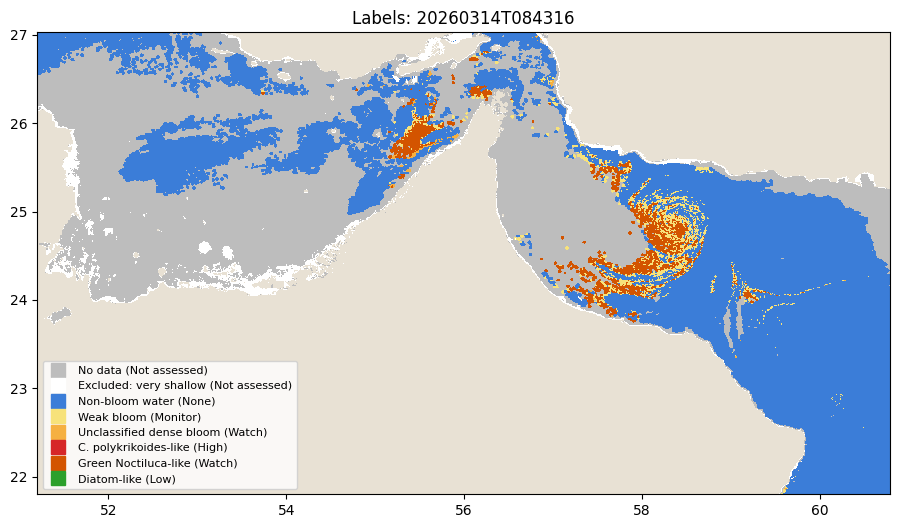

In [45]:
# Look at results

from matplotlib.colors import ListedColormap, BoundaryNorm

codes = sorted(LEGEND)
cmap = ListedColormap([LEGEND[c][2] for c in codes])
norm = BoundaryNorm([c - 0.5 for c in codes] + [codes[-1] + 0.5], cmap.N)

f = [g for g in ALL_GRIDS if "20260314" in g][0]   # change the date to view others
with xr.open_dataset(f.replace("_grid.nc", "_labels.nc")) as lab:
    L = lab["label"].values

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_facecolor("#e8e1d4")
ax.pcolormesh(LON1D, LAT1D, L, cmap=cmap, norm=norm)
handles = [plt.Line2D([], [], marker="s", ls="", color=LEGEND[c][2], markersize=10,
                      label=f"{LEGEND[c][0]} ({LEGEND[c][1]})") for c in codes if c >= 0]
ax.legend(handles=handles, loc="lower left", fontsize=8)
ax.set_title(f"Labels: {os.path.basename(f)[:15]}")
plt.show()

### 3.11 Why the blue bands are excluded
On the two main bloom dates and the test date, checks whether the negative blue reflectance at 443 nm in dense pixels comes from haze or from the bloom itself. It compares aerosol optical thickness (`aot_865`) and the Ångström exponent between dense and non-bloom pixels, and the share of negative blue as chlorophyll rises.

Result: blue reflectance is negative in 94 to 100% of dense pixels and the share rises with chlorophyll, while the Ångström exponent (about 1.1 to 1.4) does not point to dust. This points to over-correction inside dense blooms, so naming uses 500 to 700 nm only.

In [46]:
def regrid_vars(ts, names):
    """Read extra AOP variables for one pass and regrid them like the main data."""
    p = granules[ts]
    with netCDF4.Dataset(p["AOP"]) as nc:
        lat = np.ma.filled(nc["navigation_data"]["latitude"][:].astype(np.float32), np.nan)
        lon = np.ma.filled(nc["navigation_data"]["longitude"][:].astype(np.float32), np.nan)
        v = nc["geophysical_data"]["l2_flags"]; v.set_auto_maskandscale(False)
        flags = np.array(v[:]).astype(np.uint32)
    inside = (lon >= lon_min) & (lon <= lon_max) & (lat >= lat_min) & (lat <= lat_max)
    good = inside & np.isfinite(lat) & np.isfinite(lon) & ((flags & np.uint32(BAD_BITS)) == 0)
    swath = geometry.SwathDefinition(lons=lon[good], lats=lat[good])
    out = {}
    for n in names:
        arr = read_var(p["AOP"], n, (slice(None), slice(None)))
        out[n] = kd_tree.resample_nearest(swath, arr[good], GRID, radius_of_influence=2000, fill_value=np.nan)
    return out

I443_ = int(np.argmin(np.abs(WL - 443)))
for f in ALL_GRIDS:
    ts = os.path.basename(f)[:15]
    if not any(d in ts for d in ["20260214", "20260314", "20250324"]):   # your main bloom dates + test
        continue
    extra = regrid_vars(ts, ["aot_865", "angstrom"])
    with xr.open_dataset(f) as g:
        r443 = g["Rrs"].isel(wavelength=I443_).values
        chl = g["chlor_a"].values
    with xr.open_dataset(f.replace("_grid.nc", "_density.nc")) as d:
        dens = d["density_class"].values

    aot, ang = extra["aot_865"], extra["angstrom"]
    ok = np.isfinite(r443) & np.isfinite(aot) & np.isfinite(ang)
    dense = ok & (dens == 2)
    neg, pos = dense & (r443 < 0), dense & (r443 >= 0)
    clear_water = ok & (dens == 0)

    print(f"\n{ts}: {dense.sum()} dense px, {neg.sum()} with negative Rrs(443) ({neg.sum() / max(dense.sum(), 1):.0%})")
    for name, m in [("dense, negative blue", neg), ("dense, positive blue", pos), ("non-bloom water", clear_water)]:
        if m.sum():
            print(f"  {name:22s}: aot_865 {np.median(aot[m]):.3f}, angstrom {np.median(ang[m]):.2f}, "
                  f"chl {np.median(chl[m]):.1f}")
    # does negative blue follow haze, or bloom density?
    for lo, hi in [(10, 20), (20, 40), (40, 1e9)]:
        m = dense & (chl >= lo) & (chl < hi)
        if m.sum() > 20:
            print(f"  chl {lo}-{'+' if hi > 1e8 else hi}: {np.mean(r443[m] < 0):.0%} negative blue ({m.sum()} px)")


20260214T084831: 2317 dense px, 1121 with negative Rrs(443) (48%)
  dense, negative blue  : aot_865 0.094, angstrom 1.38, chl 24.4
  dense, positive blue  : aot_865 0.080, angstrom 1.36, chl 13.6
  non-bloom water       : aot_865 0.097, angstrom 1.06, chl 1.1
  chl 10-20: 33% negative blue (1369 px)
  chl 20-40: 64% negative blue (598 px)
  chl 40-+: 84% negative blue (350 px)

20260314T084316: 7048 dense px, 6840 with negative Rrs(443) (97%)
  dense, negative blue  : aot_865 0.147, angstrom 1.19, chl 15.7
  dense, positive blue  : aot_865 0.133, angstrom 1.15, chl 12.1
  non-bloom water       : aot_865 0.130, angstrom 0.90, chl 1.0
  chl 10-20: 96% negative blue (5169 px)
  chl 20-40: 100% negative blue (1826 px)
  chl 40-+: 100% negative blue (53 px)

20250324T091204: 795 dense px, 746 with negative Rrs(443) (94%)
  dense, negative blue  : aot_865 0.139, angstrom 1.06, chl 14.8
  dense, positive blue  : aot_865 0.125, angstrom 1.17, chl 12.1
  non-bloom water       : aot_865 0.121, 

## Step 4: Held-out test

### 4.1 Extended-area test, 24 March 2025
Runs the frozen pipeline (same flags, thresholds, PCA, k-means and cluster names) on the held-out pass. The area is extended to 56 to 63°E, 19 to 26.5°N to follow the bloom's documented drift down the Oman coast. NASA Earth Observatory and Copernicus describe this bloom as likely green *Noctiluca*; it was not water sampled.

Saves `20250324T091204_ext_labels.nc` (including nflh for the export) and prints the label shares of dense pixels.

**Edit `GEBCO2_PATH`** to a GEBCO tile covering the extended area.

Expected: 1,220 dense pixels, 72.1% green *Noctiluca*-like, 27.9% unclassified, 0 *C. polykrikoides*-like.

Extended test grid: 750 x 700
Good swath pixels in extended area: 36,109
Saved 20250324T091204_ext_labels.nc

Dense bloom pixels: 1220
  Unclassified dense bloom    :    340  (27.9% of dense)
  C. polykrikoides-like       :      0  (0.0% of dense)
  Green Noctiluca-like        :    880  (72.1% of dense)
  Diatom-like                 :      0  (0.0% of dense)


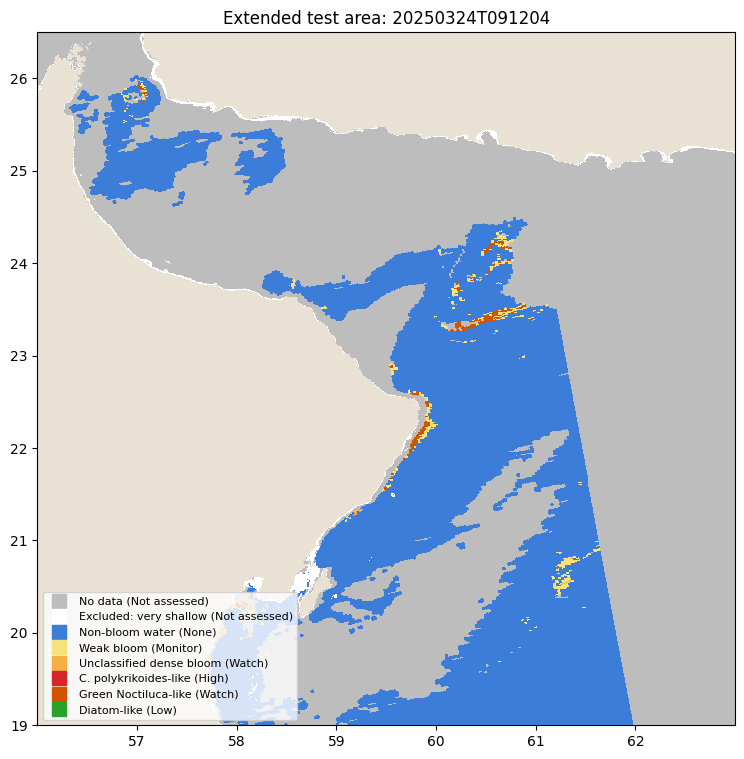

In [47]:
# Extended-area test: 24 March 2025, frozen pipeline
TEST_TS = "20250324T091204"
TEST_BBOX = (56.0, 19.0, 63.0, 26.5)          # lon_min, lat_min, lon_max, lat_max
GEBCO2_PATH = "/content/drive/MyDrive/HAB Detection Project/Datasets/GEBCO bathymetry/gebco_2026_n27.0_s18.5_w55.5_e63.5.nc"   # EDIT

# --- 1. extended grid and depth masks ---
t_lon_min, t_lat_min, t_lon_max, t_lat_max = TEST_BBOX
T_LON1D = np.arange(t_lon_min + RES / 2, t_lon_max, RES).astype(np.float32)
T_LAT1D = np.arange(t_lat_max - RES / 2, t_lat_min, -RES).astype(np.float32)
T_LON2D, T_LAT2D = np.meshgrid(T_LON1D, T_LAT1D)
T_GRID = geometry.GridDefinition(lons=T_LON2D, lats=T_LAT2D)

with xr.open_dataset(GEBCO2_PATH) as geb2:
    elev2 = geb2["elevation"].sel(lat=xr.DataArray(T_LAT1D, dims="lat"),
                                  lon=xr.DataArray(T_LON1D, dims="lon"),
                                  method="nearest").values.astype(np.float32)
T_DEPTH = -elev2
T_SEA = T_DEPTH > 0
T_VERY_SHALLOW = T_SEA & (T_DEPTH < DEPTH_MIN)
T_MASK = T_DEPTH < DEPTH_MIN                     # land or very shallow
T_SHALLOW_FLAG = (T_DEPTH >= DEPTH_MIN) & (T_DEPTH < DEPTH_FLAG)
print(f"Extended test grid: {T_LAT1D.size} x {T_LON1D.size}")

# --- 2. read the pass and regrid (same quality flags as everywhere else) ---
p = granules[TEST_TS]
with netCDF4.Dataset(p["AOP"]) as nc:
    lat = np.ma.filled(nc["navigation_data"]["latitude"][:].astype(np.float32), np.nan)
    lon = np.ma.filled(nc["navigation_data"]["longitude"][:].astype(np.float32), np.nan)
inside = ((lon >= t_lon_min - 0.05) & (lon <= t_lon_max + 0.05) &
          (lat >= t_lat_min - 0.05) & (lat <= t_lat_max + 0.05))
rows, cols = np.where(inside.any(axis=1))[0], np.where(inside.any(axis=0))[0]
sl = (slice(rows[0], rows[-1] + 1), slice(cols[0], cols[-1] + 1))
lat, lon, inside = lat[sl], lon[sl], inside[sl]

rrs = read_var(p["AOP"], "Rrs", sl + (slice(None),))
with netCDF4.Dataset(p["AOP"]) as nc:
    v = nc["geophysical_data"]["l2_flags"]; v.set_auto_maskandscale(False)
    flags = np.array(v[sl]).astype(np.uint32)
chl = read_var(p["BGC"], "chlor_a", sl)
nflh = read_var(p["AOP"], "nflh", sl)
bbp = find_bbp560(p["IOP"], sl)

vis = (WL >= 400) & (WL <= 700)
good = (inside & np.isfinite(lat) & np.isfinite(lon)
        & ((flags & np.uint32(BAD_BITS)) == 0)
        & np.all(np.isfinite(rrs[..., vis]), axis=2))
print(f"Good swath pixels in extended area: {good.sum():,}")

swath = geometry.SwathDefinition(lons=lon[good], lats=lat[good])
def rs(a):
    return kd_tree.resample_nearest(swath, a[good], T_GRID, radius_of_influence=2000, fill_value=np.nan)
G_rrs, G_chl, G_nflh, G_bbp = rs(rrs), rs(chl), rs(nflh), rs(bbp)
del rrs
for a in (G_rrs, G_chl, G_nflh, G_bbp):
    a[T_MASK] = np.nan

# --- 3. density gate (same thresholds) ---
dens = np.full(G_chl.shape, -1, np.int8)
ok = np.isfinite(G_chl)
dense = ok & (G_chl >= CHL_DENSE) & np.isfinite(G_nflh) & (G_nflh > NFLH_THR)
dens[ok & (G_chl < CHL_WEAK)] = 0
dens[ok & (G_chl >= CHL_WEAK)] = 1
dens[dense] = 2

# --- 4. frozen PCA + frozen k-means ---
R = G_rrs[..., USE]
norm = np.linalg.norm(R, axis=2)
valid = np.all(np.isfinite(R), axis=2) & (norm > 0)
cl = np.full(valid.shape, -1, np.int16)
cl[valid] = assign_clusters(pca.transform(R[valid] / norm[valid][:, None]))

# --- 5. frozen cluster names + precedence table ---
L = np.full(cl.shape, -1, np.int8)
L[T_SEA] = 0
L[T_VERY_SHALLOW] = 1
k = np.where(cl >= 0, cl, 0)
todo = T_SEA & ~T_VERY_SHALLOW & (cl >= 0) & np.isfinite(G_chl)
r = todo & (G_chl < 5);                                      L[r] = 2; todo &= ~r
r = todo & best_is_water[k] & (dens != 2);                   L[r] = 2; todo &= ~r
r = todo & (dens == 1);                                      L[r] = 3; todo &= ~r
r = todo & (dens == 2) & (~named_arr[k] | best_is_water[k]); L[r] = 4; todo &= ~r
r = todo & (dens == 2) & named_arr[k];                       L[r] = species_arr[k][r]; todo &= ~r
L[todo] = 0
conf = np.where(np.isin(L, [5, 6, 7]), conf_arr[k], np.nan).astype(np.float32)

# --- 6. save ---
out_path = os.path.join(OUT_DIRS["test"], f"{TEST_TS}_ext_labels.nc")
xr.Dataset({"label": (("lat", "lon"), L),
            "confidence": (("lat", "lon"), conf),
            "cluster": (("lat", "lon"), cl),
            "density_class": (("lat", "lon"), dens),
            "chlor_a": (("lat", "lon"), G_chl.astype(np.float32)),
            "nflh": (("lat", "lon"), G_nflh.astype(np.float32)),      # needed by the export cells
            "shallow_flag": (("lat", "lon"), T_SHALLOW_FLAG.astype(np.int8)),
            "depth": (("lat", "lon"), np.where(T_MASK, np.nan, T_DEPTH).astype(np.float32))},
           coords={"lat": T_LAT1D, "lon": T_LON1D},
           attrs={"timestamp": TEST_TS, "role": "test",
                  "bbox": str(TEST_BBOX), "note": "extended test area, frozen pipeline"}
           ).to_netcdf(out_path)
print("Saved", os.path.basename(out_path))

# --- 7. results ---
nd = int((dens == 2).sum())
print(f"\nDense bloom pixels: {nd}")
for c in [4, 5, 6, 7]:
    n = int((L == c).sum())
    print(f"  {LEGEND[c][0]:28s}: {n:6d}  ({n / max(nd, 1):.1%} of dense)")

codes = sorted(LEGEND)
cmap = ListedColormap([LEGEND[c][2] for c in codes])
norm_c = BoundaryNorm([c - 0.5 for c in codes] + [codes[-1] + 0.5], cmap.N)
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_facecolor("#e8e1d4")
ax.pcolormesh(T_LON1D, T_LAT1D, L, cmap=cmap, norm=norm_c)
handles = [plt.Line2D([], [], marker="s", ls="", color=LEGEND[c][2], markersize=10,
                      label=f"{LEGEND[c][0]} ({LEGEND[c][1]})") for c in codes if c >= 0]
ax.legend(handles=handles, loc="lower left", fontsize=8)
ax.set_title(f"Extended test area: {TEST_TS}")
plt.show()

### 4.2 What is labelled non-bloom on the test date?
Breaks the non-bloom pixels down by chlorophyll and depth. A small share of offshore pixels with moderate chlorophyll (about 1.5%) end up as non-bloom through the water-type rule, which we list as a limitation.

In [48]:
with xr.open_dataset(os.path.join(OUT_DIRS["test"], f"{TEST_TS}_ext_labels.nc")) as e:
    L_, chl_, dep_ = e["label"].values, e["chlor_a"].values, e["depth"].values
nb = (L_ == 2) & np.isfinite(chl_)
print(f"Non-bloom pixels: {nb.sum():,}")
for lo, hi in [(0, 1), (1, 5), (5, 10), (10, 1e9)]:
    m = nb & (chl_ >= lo) & (chl_ < hi)
    print(f"  chl {lo}-{'+' if hi > 1e8 else hi}: {m.sum():,} px, of which offshore (>30 m): {(m & (dep_ > 30)).sum():,}")

Non-bloom pixels: 103,504
  chl 0-1: 31,488 px, of which offshore (>30 m): 30,506
  chl 1-5: 69,619 px, of which offshore (>30 m): 66,118
  chl 5-10: 1,966 px, of which offshore (>30 m): 1,183
  chl 10-+: 431 px, of which offshore (>30 m): 303


## Step 5: Validation

### 5.1 Load all results
Loads the labels, density classes, clusters and chlorophyll of every date into `RESULTS`; the test date uses the extended-area file. `SUMMARY` collects the validation numbers and is saved in 5.5.

In [49]:
# Load all results

import json
from collections import OrderedDict

TEST_TS = "20250324T091204"
SCENES = []
for f in ALL_GRIDS:
    ts, role = os.path.basename(f)[:15], role_of(f)
    if role != "test":                 # the test date uses the extended-area file instead
        SCENES.append((ts, role))
SCENES.append((TEST_TS, "test"))

def load_result(ts, role):
    if role == "test":
        with xr.open_dataset(os.path.join(OUT_DIRS["test"], f"{ts}_ext_labels.nc")) as e:
            return {"L": e["label"].values,
                    "dens": e["density_class"].values, "cl": e["cluster"].values,
                    "chl": e["chlor_a"].values,
                    "lat": e["lat"].values, "lon": e["lon"].values}
    f = os.path.join(OUT_DIRS["analysis"], f"{ts}_grid.nc")
    with xr.open_dataset(f.replace("_grid.nc", "_labels.nc")) as lab:
        L, cl = lab["label"].values, lab["cluster"].values
    with xr.open_dataset(f.replace("_grid.nc", "_density.nc")) as d:
        dens = d["density_class"].values
    with xr.open_dataset(f) as g:
        chl = g["chlor_a"].values
    return {"L": L, "dens": dens, "cl": cl, "chl": chl,
            "lat": LAT1D, "lon": LON1D}

RESULTS = {ts: dict(role=role, **load_result(ts, role)) for ts, role in SCENES}
SUMMARY = OrderedDict()
print(f"Loaded {len(RESULTS)} scenes:", [(ts[:8], r["role"]) for ts, r in RESULTS.items()])

Loaded 12 scenes: [('20241011', 'calm'), ('20241030', 'analysis'), ('20241203', 'analysis'), ('20241209', 'analysis'), ('20250123', 'analysis'), ('20250406', 'analysis'), ('20251002', 'analysis'), ('20251025', 'calm'), ('20251116', 'analysis'), ('20260214', 'analysis'), ('20260314', 'analysis'), ('20250324', 'test')]


### 5.2 V1: held-out test
The share of each label among dense pixels on 24 March 2025, checked against our criterion: under 10% *C. polykrikoides*-like, with most pixels *Noctiluca*-like or unclassified. This is a false-alarm check only. No confirmed *C. polykrikoides* bloom exists in the PACE record yet, so detection cannot be tested.

In [50]:
# V1, the held-out test date

r = RESULTS[TEST_TS]
dense = r["dens"] == 2
nd = int(dense.sum())
counts = {LEGEND[c][0]: int((r["L"] == c).sum()) for c in [4, 5, 6, 7]}
shares = {k: round(100 * v / max(nd, 1), 1) for k, v in counts.items()}

cp = shares["C. polykrikoides-like"]
passed = cp < 10 and (shares["Green Noctiluca-like"] + shares["Unclassified dense bloom"]) > 50

print(f"Test date {TEST_TS[:8]} (extended area), dense bloom pixels: {nd}")
for k in counts:
    print(f"  {k:28s} {counts[k]:6d}  ({shares[k]}%)")
print(f"\nCriterion: <10% C. polykrikoides-like "
      f"and majority Noctiluca-like or unclassified -> {'PASS' if passed else 'FAIL'}")
print("Note: this is a false-alarm (true-negative) check only. No confirmed C. polykrikoides "
      "event exists in PACE's lifetime to test detection.")

SUMMARY["test"] = {
    "date": "2025-03-24", "timestamp": TEST_TS,
    "area": "Gulf of Oman and Oman's Arabian Sea coast (56-63E, 19-26.5N), following the bloom's documented drift",
    "documented_as": "likely green Noctiluca (NASA Earth Observatory, Copernicus); not confirmed by water sampling",
    "dense_pixels": nd, "counts": counts, "percent_of_dense": shares,
    "criterion": "<10% C. polykrikoides-like and majority Noctiluca-like or unclassified",
    "result": "PASS" if passed else "FAIL",
    "type": "false-alarm (true-negative) check only",
}

Test date 20250324 (extended area), dense bloom pixels: 1220
  Unclassified dense bloom        340  (27.9%)
  C. polykrikoides-like             0  (0.0%)
  Green Noctiluca-like            880  (72.1%)
  Diatom-like                       0  (0.0%)

Criterion: <10% C. polykrikoides-like and majority Noctiluca-like or unclassified -> PASS
Note: this is a false-alarm (true-negative) check only. No confirmed C. polykrikoides event exists in PACE's lifetime to test detection.


### 5.3 Calm dates and plausibility of the Noctiluca labels
- **Calm dates:** on 11 Oct 2024 and 25 Oct 2025 we expect almost no dense pixels and no *C. polykrikoides*-like labels. These dates helped fit k-means but not the names, so this is a supporting check rather than a held-out one.
- **Season and place:** green *Noctiluca* blooms in winter on the Sea of Oman side. We check the share of *Noctiluca*-like pixels on November to March dates and east of 56.4°E (Musandam).

In [51]:
# 2, false alarms on calm dates, and V3, plausibility

import datetime

# V2: calm dates
print("V3. False-alarm check on low-bloom reference dates:")
calm = {}
for ts, r in RESULTS.items():
    if r["role"] == "calm":
        nd = int((r["dens"] == 2).sum())
        calm[ts[:8]] = {"dense_pixels": nd,
                        "cp_like": int((r["L"] == 5).sum()),
                        "noctiluca_like": int((r["L"] == 6).sum()),
                        "unclassified_dense": int((r["L"] == 4).sum())}
        print(f"  {ts[:8]}: dense {nd}, C. polykrikoides-like {calm[ts[:8]]['cp_like']}, "
              f"Noctiluca-like {calm[ts[:8]]['noctiluca_like']}, unclassified {calm[ts[:8]]['unclassified_dense']}")
SUMMARY["calm_dates"] = calm

# V3: plausibility of the Noctiluca-like labels (season and place)
print("\nV4. Plausibility of green Noctiluca-like labels:")
winter = {11, 12, 1, 2, 3}
tot_noc, tot_noc_winter, tot_noc_oman = 0, 0, 0
per_date = []
for ts, r in RESULTS.items():
    month = int(ts[4:6])
    noc = r["L"] == 6
    n = int(noc.sum())
    lon2d = np.broadcast_to(r["lon"][None, :], r["L"].shape)
    n_oman = int((noc & (lon2d >= 56.4)).sum())     # east of Musandam: Gulf of Oman / Arabian Sea side
    tot_noc += n
    tot_noc_winter += n if month in winter else 0
    tot_noc_oman += n_oman
    per_date.append({"date": ts[:8], "role": r["role"],
                     "month": datetime.date(2000, month, 1).strftime("%b"),
                     "noctiluca_like": n, "of_which_gulf_of_oman_side": n_oman,
                     "cp_like": int((r["L"] == 5).sum())})
print(pd.DataFrame(per_date).to_string(index=False))
season_share = tot_noc_winter / tot_noc if tot_noc else None
place_share = tot_noc_oman / tot_noc if tot_noc else None
print(f"\nNoctiluca-like pixels on Nov-Mar dates: {season_share:.0%}" if season_share is not None else "")
print(f"Noctiluca-like pixels on the Gulf of Oman / Arabian Sea side: {place_share:.0%}" if place_share is not None else "")
print("C. polykrikoides-like pixels on any date:", sum(d["cp_like"] for d in per_date))

SUMMARY["plausibility"] = {"noctiluca_like_total": tot_noc,
                           "share_in_nov_mar": round(season_share, 3) if season_share is not None else None,
                           "share_gulf_of_oman_side": round(place_share, 3) if place_share is not None else None,
                           "cp_like_total": sum(d["cp_like"] for d in per_date),
                           "per_date": per_date}

V3. False-alarm check on low-bloom reference dates:
  20241011: dense 26, C. polykrikoides-like 0, Noctiluca-like 23, unclassified 3
  20251025: dense 0, C. polykrikoides-like 0, Noctiluca-like 0, unclassified 0

V4. Plausibility of green Noctiluca-like labels:
    date     role month  noctiluca_like  of_which_gulf_of_oman_side  cp_like
20241011     calm   Oct              23                          23        0
20241030 analysis   Oct               4                           0        0
20241203 analysis   Dec              11                           0        0
20241209 analysis   Dec               0                           0        0
20250123 analysis   Jan               7                           0        0
20250406 analysis   Apr              87                          18        0
20251002 analysis   Oct               0                           0        0
20251025     calm   Oct               0                           0        0
20251116 analysis   Nov               8      

### 5.4 Synthetic test and the 430 vs 500 nm comparison
- **Synthetic test:** reruns the diluted *C. polykrikoides* check from 3.8 and records it (consistency check only).
- **Band range:** counts how many dense pixels a naive single comparison would call *C. polykrikoides* over 430 to 700 nm, over 500 to 700 nm, and with the final pipeline. Including the over-corrected blue bands would have raised false red tide alarms on 8,803 dense pixels; the final pipeline raises none.

In [52]:
# V4 synthetic test, and V5 the 430 versus 500 nm comparison

# V4: synthetic C. polykrikoides recognition (consistency check, not validation)
def name_spectrum(spec):
    spec = unit(spec)
    cd2, cd2m = second_deriv(spec, np.ones(len(WL_USE), bool))
    main = {n: sam_deg(spec, REFS[n]["curve"], REFS[n]["mask"] & CMP) for n in ref_names}
    deriv = {n: sam_deg(cd2, REFS[n]["d2"], REFS[n]["d2mask"] & cd2m) for n in ref_names}
    best, second = sorted(main, key=main.get)[:2]
    pair = sam_deg(REFS[best]["curve"], REFS[second]["curve"],
                   REFS[best]["mask"] & REFS[second]["mask"] & CMP)
    conf = float(np.clip((main[second] - main[best]) / pair, 0, 1))
    return best, round(conf, 2), (conf >= MARGIN_MIN and min(deriv, key=deriv.get) == best)

cpref = np.nan_to_num(REFS["C. polykrikoides"]["curve"])
clear = REFS["Clear water"]["curve"]
rng_t = np.random.default_rng(42)
synth = []
for mix in [0.0, 0.2, 0.4]:
    for noise in [0.0, 0.01, 0.02]:
        best, conf, named = name_spectrum((1 - mix) * cpref + mix * clear + rng_t.normal(0, noise, len(cpref)))
        synth.append({"clear_water_mixed": mix, "noise": noise, "best": best, "confidence": conf, "named": bool(named)})
print("V5. Synthetic test:")
print(pd.DataFrame(synth).to_string(index=False))
SUMMARY["synthetic_test"] = {"note": "Consistency check: the reference is used both to build and detect. Not validation.",
                             "results": synth}

# V5: what a naive comparison over 430-700 nm would have said
def main_best(spec, wl_min):
    m = WL_USE >= wl_min
    ang = {n: sam_deg(spec, REFS[n]["curve"], REFS[n]["mask"] & m) for n in ref_names}
    return min(ang, key=ang.get)

cp_clusters_430 = [k for k in CLUSTERS.index if main_best(naming_spec[k], 430) == "C. polykrikoides"]
cp_clusters_500 = [k for k in CLUSTERS.index if main_best(naming_spec[k], 500) == "C. polykrikoides"]
naive_430 = sum(int(((r["dens"] == 2) & np.isin(r["cl"], cp_clusters_430)).sum()) for r in RESULTS.values())
naive_500 = sum(int(((r["dens"] == 2) & np.isin(r["cl"], cp_clusters_500)).sum()) for r in RESULTS.values())
print(f"\nV6. Dense pixels a naive single comparison would call C. polykrikoides:")
print(f"  430-700 nm (includes over-corrected blue): {naive_430:,} px  (clusters {cp_clusters_430})")
print(f"  500-700 nm:                                {naive_500:,} px  (clusters {cp_clusters_500})")
print(f"  Final pipeline (500-700 nm + derivative agreement + margin rule): 0 px")
SUMMARY["blue_band_sensitivity"] = {"naive_430_cp_pixels": naive_430, "naive_500_cp_pixels": naive_500,
                                    "final_pipeline_cp_pixels": 0,
                                    "reason": "Rrs < ~490 nm negative in 94-100% of dense pixels on bloom dates; "
                                              "share rises with chlorophyll, Angstrom 1.1-1.4 (not dust)"}

V5. Synthetic test:
 clear_water_mixed  noise             best  confidence  named
               0.0   0.00 C. polykrikoides        1.00   True
               0.0   0.01 C. polykrikoides        0.82   True
               0.0   0.02 C. polykrikoides        0.74   True
               0.2   0.00 C. polykrikoides        0.68   True
               0.2   0.01 C. polykrikoides        0.59   True
               0.2   0.02 C. polykrikoides        0.47   True
               0.4   0.00 C. polykrikoides        0.27   True
               0.4   0.01 C. polykrikoides        0.27   True
               0.4   0.02 C. polykrikoides        0.22  False

V6. Dense pixels a naive single comparison would call C. polykrikoides:
  430-700 nm (includes over-corrected blue): 8,803 px  (clusters [9, 20, 21, 22])
  500-700 nm:                                0 px  (clusters [])
  Final pipeline (500-700 nm + derivative agreement + margin rule): 0 px


### 5.5 Save the summary
Adds the thresholds, method details and limitations to `SUMMARY` and saves `export/summary.json`, which the map uses for its results and limitations panels.

In [53]:
# Save the summary

EXPORT_DIR = os.path.join(PACE_DIR, "export")
os.makedirs(EXPORT_DIR, exist_ok=True)

SUMMARY["thresholds"] = {
    "chl_weak_mg_m3": CHL_WEAK, "chl_dense_mg_m3": CHL_DENSE,
    "nflh_raised_W_m2_um_sr": round(float(NFLH_THR), 4),
    "nflh_rule": "95th percentile of nflh in normal water (chl < 1) on 2 low-bloom dates",
    "margin_min": MARGIN_MIN, "main_comparison_nm": [COMPARE_MIN, float(WL_USE.max())],
    "depth_excluded_below_m": DEPTH_MIN, "depth_flagged_below_m": DEPTH_FLAG,
}
SUMMARY["method"] = {
    "sensor": "NASA PACE OCI Level-2 (AOP, BGC, IOP), regridded to 0.01 deg",
    "pca_components": int(N_PC), "pca_variance_explained": round(float(np.sum(pca.explained_variance_ratio_)), 4),
    "kmeans": f"two-level: {N_COARSE} coarse x {N_FINE} fine = {N_CLUSTERS} clusters",
    "naming": "SAM on normalized Rrs (500-700 nm) + smoothed 2nd-derivative SAM; species only if both agree and margin >= 0.25",
    "references": {n: {"source": REFS[n]["source"], "region": REFS[n]["region"]} for n in REFS},
}
SUMMARY["limitations"] = [
    "No confirmed C. polykrikoides event in PACE's lifetime: detection (true positive) is untested on real data.",
    "Test bloom species documented by NASA/Copernicus as likely green Noctiluca, not confirmed by water sampling.",
    "References are digitized from published figures (Korea; northern Arabian Sea), not Gulf field measurements; "
    "digitized and PACE spectra of similar water differ by ~13 deg.",
    "Diatom reference resembles clear water (moderate-biomass diatoms); dense diatom blooms would appear as unclassified.",
    "Blue bands (<500 nm) excluded from main matching: over-corrected in dense blooms.",
    "Water shallower than 5 m not assessed; 5-15 m flagged. 1 km pixels cannot resolve desalination intakes.",
    "Bloom spectra in training dominated by two late-winter 2026 events.",
    "Some passes unusable due to cloud or high viewing angle (edge of swath).",
]

with open(os.path.join(EXPORT_DIR, "summary.json"), "w") as fp:
    json.dump(SUMMARY, fp, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved summary.json with sections:", list(SUMMARY))

Saved summary.json with sections: ['test', 'calm_dates', 'plausibility', 'synthetic_test', 'blue_band_sensitivity', 'thresholds', 'method', 'limitations']


## Step 6: Export for the interactive map

### 6.1 Set up the export folder
Installs rasterio, clears old exports (keeping `summary.json` and the PCA chart) and defines `get_layers()`, which collects every layer the map needs for one date together with its exact georeference. The map opens on 14 March 2026 by default.

In [54]:
# Set up the export folder

!pip install -q rasterio
import rasterio, shutil
import matplotlib.colors as mcolors
from rasterio.transform import from_origin
from rasterio import features
from scipy import ndimage

EXPORT_DIR = os.path.join(PACE_DIR, "export")
os.makedirs(EXPORT_DIR, exist_ok=True)

# clear old exports (from the early test export), keep the summary and PCA chart
KEEP = {"summary.json", "pca_variance.png"}
for fn in os.listdir(EXPORT_DIR):
    path = os.path.join(EXPORT_DIR, fn)
    if fn not in KEEP and os.path.isfile(path):
        os.remove(path)

DEFAULT_SCENE = "20260314T084316"   # the map opens on this date
NASA_URL = "https://science.nasa.gov/earth/earth-observatory/a-swirl-of-a-day-for-phytoplankton-154086"
COPERNICUS_URL = "https://eu-space.europa.eu/components/earth-observation-copernicus/image-of-day/algal-bloom-gulf-oman"

def get_layers(ts, role):
    """All per-pixel layers for one scene, plus its georeference."""
    if role == "test":
        with xr.open_dataset(os.path.join(OUT_DIRS["test"], f"{ts}_ext_labels.nc")) as e:
            lay = {k: e[k].values for k in ["label", "confidence", "cluster", "density_class",
                                             "chlor_a", "shallow_flag", "depth", "nflh"]}
            lat, lon = e["lat"].values, e["lon"].values
    else:
        f = os.path.join(OUT_DIRS["analysis"], f"{ts}_grid.nc")
        with xr.open_dataset(f.replace("_grid.nc", "_labels.nc")) as lab:
            lay = {k: lab[k].values for k in ["label", "confidence", "cluster", "shallow_flag"]}
        with xr.open_dataset(f.replace("_grid.nc", "_density.nc")) as d:
            lay["density_class"] = d["density_class"].values
        with xr.open_dataset(f) as g:
            lay["chlor_a"] = g["chlor_a"].values
            lay["nflh"] = g["nflh"].values
        lay["depth"] = np.where(SHALLOW_OR_LAND, np.nan, DEPTH)
        lat, lon = LAT1D, LON1D
    res = float(abs(lon[1] - lon[0]))
    west, north = float(lon[0] - res / 2), float(lat[0] + res / 2)
    east, south = float(lon[-1] + res / 2), float(lat[-1] - res / 2)
    lay["transform"] = from_origin(west, north, res, res)
    lay["bounds"] = [[round(south, 4), round(west, 4)], [round(north, 4), round(east, 4)]]
    return lay

print("Export folder ready:", EXPORT_DIR)

Export folder ready: /content/drive/MyDrive/HAB Detection Project/Datasets/Satellites/Hyperspectral/PACE/export


### 6.2 Images, GeoTIFFs and scenes.json
For every date:
- `<timestamp>_grid.tif`: 8 bands (label, chlorophyll, density class, cluster, shallow flag, depth, confidence, nflh), read by the map when a pixel is clicked
- `<timestamp>_chl.png`: chlorophyll, log scale 0.01 to 20 mg/m³, turbo color map
- `<timestamp>_nflh.png`: fluorescence, linear 0 to 1 W m⁻² µm⁻¹ sr⁻¹, viridis color map
- `<timestamp>_labels.png`: the label map in legend colors

`scenes.json` lists every date with its role, bounds, files and label counts. The test date also carries the NASA and Copernicus links.

In [55]:
# Images, GeoTIFFs and scenes.json

def label_rgba(L):
    rgba = np.zeros(L.shape + (4,))
    for code, (name, tier, color) in LEGEND.items():
        if code >= 0:
            rgba[L == code] = mcolors.to_rgba(color)
    rgba[L == 1, 3] = 0.5          # very shallow: semi-transparent white
    return rgba

ROLE_LABEL = {"analysis": "Analysis date", "calm": "Low-bloom reference date", "test": "Held-out test date"}
scenes = []

for ts, role in SCENES:
    lay = get_layers(ts, role)
    L, chl, nf = lay["label"], lay["chlor_a"], lay["nflh"]
    h, w = L.shape

    # 1) GeoTIFF: per-pixel values for click popups (8 bands)
    bands = [("label", L), ("chlor_a", chl), ("density_class", lay["density_class"]),
             ("cluster", lay["cluster"]), ("shallow_flag", lay["shallow_flag"]),
             ("depth", lay["depth"]), ("confidence", lay["confidence"]), ("nflh", nf)]
    with rasterio.open(os.path.join(EXPORT_DIR, f"{ts}_grid.tif"), "w", driver="GTiff",
                       height=h, width=w, count=len(bands), dtype="float32", crs="EPSG:4326",
                       transform=lay["transform"], nodata=np.nan, compress="deflate") as dst:
        for i, (_, arr) in enumerate(bands, 1):
            dst.write(np.asarray(arr, dtype=np.float32), i)
        dst.descriptions = tuple(n for n, _ in bands)

    # 2) PNG overlays: chlorophyll, fluorescence and labels
    rgba = plt.get_cmap("turbo")(LogNorm(0.01, 20, clip=True)(np.where(np.isfinite(chl), chl, 0.01)))
    rgba[~np.isfinite(chl), 3] = 0
    plt.imsave(os.path.join(EXPORT_DIR, f"{ts}_chl.png"), rgba)

    rgba = plt.get_cmap("viridis")(mcolors.Normalize(0, 1, clip=True)(np.where(np.isfinite(nf), nf, 0)))
    rgba[~np.isfinite(nf), 3] = 0
    plt.imsave(os.path.join(EXPORT_DIR, f"{ts}_nflh.png"), rgba)

    plt.imsave(os.path.join(EXPORT_DIR, f"{ts}_labels.png"), label_rgba(L))

    # 3) scene entry
    sea = L >= 0
    counts = {LEGEND[c][0]: int((L == c).sum()) for c in range(0, 8)}
    entry = {
        "timestamp": ts, "date": f"{ts[:4]}-{ts[4:6]}-{ts[6:8]}", "role": role,
        "role_label": ROLE_LABEL[role], "bounds": lay["bounds"],
        "files": {"grid": f"{ts}_grid.tif", "chl": f"{ts}_chl.png", "nflh": f"{ts}_nflh.png",
                  "labels_png": f"{ts}_labels.png", "labels_geojson": f"{ts}_labels.geojson"},
        "label_counts": counts,
        "dense_pixels": int((lay["density_class"] == 2).sum()),
        "assessed_water_pct": round(100 * float((L[sea] >= 2).mean()), 1),
    }
    if role == "test":
        entry["note"] = ("Test date: bloom documented by NASA Earth Observatory and Copernicus as likely "
                         "green Noctiluca; species not confirmed by water sampling. Area extended to follow "
                         "the bloom's documented drift into the Arabian Sea.")
        entry["links"] = {"NASA Earth Observatory": NASA_URL, "Copernicus": COPERNICUS_URL}
    elif role == "calm":
        entry["note"] = "Low-bloom reference date, used to set the normal-water fluorescence threshold."
    scenes.append(entry)
    print(f"{ts[:8]} ({role}): exported, {entry['dense_pixels']} dense px")

with open(os.path.join(EXPORT_DIR, "scenes.json"), "w") as fp:
    json.dump({"default_scene": DEFAULT_SCENE, "test_scene": TEST_TS, "crs": "EPSG:4326",
               "resolution_deg": 0.01, "bounds_format": "[[south, west], [north, east]] (Leaflet order)",
               "nflh_units": "W m^-2 um^-1 sr^-1", "nflh_raised_threshold": round(float(NFLH_THR), 4),
               "nflh_png_scale": "viridis, linear 0-1",
               "scenes": scenes}, fp, indent=2)
print("Saved scenes.json")

20241011 (calm): exported, 26 dense px
20241030 (analysis): exported, 4 dense px
20241203 (analysis): exported, 11 dense px
20241209 (analysis): exported, 0 dense px
20250123 (analysis): exported, 7 dense px
20250406 (analysis): exported, 136 dense px
20251002 (analysis): exported, 0 dense px
20251025 (calm): exported, 0 dense px
20251116 (analysis): exported, 8 dense px
20260214 (analysis): exported, 2317 dense px
20260314 (analysis): exported, 7048 dense px
20250324 (test): exported, 1220 dense px
Saved scenes.json


### 6.3 Bloom patches as GeoJSON
Turns bloom areas (weak, unclassified dense and the three species labels) into outlined patches, grouped by label, cluster and shallow flag so each patch is uniform. Each patch carries the popup fields: label, risk tier, color, confidence (species labels only), closest reference, density class, median chlorophyll, size, shallow zone, cluster and date.

In [56]:
# Bloom patches as GeoJSON

BLOOM_CODES = [3, 4, 5, 6, 7]     # weak, unclassified dense, and the three species labels

for ts, role in SCENES:
    lay = get_layers(ts, role)
    L, cl, sh, chl = lay["label"], lay["cluster"], lay["shallow_flag"], lay["chlor_a"]
    bloom = np.isin(L, BLOOM_CODES)
    key = np.where(bloom, L.astype(np.int64) * 10000 + np.clip(cl, 0, None).astype(np.int64) * 10
                   + sh.astype(np.int64), -1)
    feats = []
    for v in np.unique(key[key >= 0]):
        code, cid, shz = int(v // 10000), int((v % 10000) // 10), int(v % 10)
        comp, n = ndimage.label(key == v, structure=np.ones((3, 3)))
        ids = np.arange(1, n + 1)
        npx = np.bincount(comp.ravel(), minlength=n + 1)
        med = ndimage.median(np.nan_to_num(chl), labels=comp, index=ids)
        row = CLUSTERS.loc[cid] if cid in CLUSTERS.index else None
        for geom, cval in features.shapes(comp.astype(np.int32), mask=comp > 0,
                                          transform=lay["transform"], connectivity=8):
            i = int(cval)
            feats.append({"type": "Feature", "geometry": geom, "properties": {
                "label": LEGEND[code][0], "label_code": code,
                "risk_tier": LEGEND[code][1], "color": LEGEND[code][2],
                "confidence": round(float(row["confidence"]), 2) if code in (5, 6, 7) and row is not None else None,
                "closest_reference": row["best"] if row is not None else None,
                "density_class": 2 if code >= 4 else 1,
                "chl_median": round(float(med[i - 1]), 2),
                "n_pixels": int(npx[i]),
                "shallow_zone": bool(shz),
                "cluster_id": cid, "date": f"{ts[:4]}-{ts[4:6]}-{ts[6:8]}", "timestamp": ts}})
    with open(os.path.join(EXPORT_DIR, f"{ts}_labels.geojson"), "w") as fp:
        json.dump({"type": "FeatureCollection", "features": feats}, fp)
    print(f"{ts[:8]}: {len(feats)} bloom patches")

20241011: 15 bloom patches
20241030: 9 bloom patches
20241203: 11 bloom patches
20241209: 7 bloom patches
20250123: 24 bloom patches
20250406: 111 bloom patches
20251002: 12 bloom patches
20251025: 0 bloom patches
20251116: 30 bloom patches
20260214: 1524 bloom patches
20260314: 1319 bloom patches
20250324: 297 bloom patches


### 6.4 Legend, spectra, README and ZIP
Writes `legend.json` (codes, names, tiers and colors), `references.json` (the 6 reference curves), `cluster_spectra.json` (each cluster's spectrum and matching results) and a README for the map, then zips the export folder into `export_for_map.zip`.

**Final output:** the `export/` folder and `export_for_map.zip`, which the interactive map loads.

In [57]:
# Legend, spectra, README and ZIP

def tolist(arr, nd=5):
    return [None if not np.isfinite(x) else round(float(x), nd) for x in arr]

# legend.json
with open(os.path.join(EXPORT_DIR, "legend.json"), "w") as fp:
    json.dump([{"code": c, "name": n, "risk_tier": t, "color": col, "show_on_map": c >= 0}
               for c, (n, t, col) in sorted(LEGEND.items())], fp, indent=2)

# references.json
with open(os.path.join(EXPORT_DIR, "references.json"), "w") as fp:
    json.dump({"wavelengths_nm": tolist(WL_USE, 1), "main_comparison_from_nm": COMPARE_MIN,
               "note": "Curves normalized to unit length (shape only). Plot from 500 nm to show what the main comparison used.",
               "references": {n: {"values": tolist(r["curve"]), "kind": r["kind"],
                                  "source": r["source"], "region": r["region"]} for n, r in REFS.items()}},
              fp, indent=2)

# cluster_spectra.json
def cname(row):
    if row["best_is_water"]:
        return row["best"]
    return f"{row['best']}-like" if row["named"] else "Unclassified"

clusters_out = {}
for k, row in CLUSTERS.iterrows():
    clusters_out[str(k)] = {
        "spectrum": tolist(naming_spec[k]), "spectrum_from": row["spec_used"],
        "cluster_name": cname(row), "best": row["best"], "angle_best_deg": float(row["angle_best"]),
        "runner_up": row["runner_up"], "angle_runner_up_deg": float(row["angle_2nd"]),
        "reference_gap_deg": float(row["ref_gap"]),
        "confidence": float(row["confidence"]), "derivative_best": row["deriv_best"],
        "named": bool(row["named"]), "best_is_water": bool(row["best_is_water"]),
        "pixels": int(row["pixels"]), "dense_percent": float(row["dense_%"]),
        "mean_chl": None if not np.isfinite(mean_chl[k]) else round(float(mean_chl[k]), 2)}
with open(os.path.join(EXPORT_DIR, "cluster_spectra.json"), "w") as fp:
    json.dump({"wavelengths_nm": tolist(WL_USE, 1),
               "confidence_formula": "(angle_runner_up_deg - angle_best_deg) / reference_gap_deg, clipped to 0-1",
               "clusters": clusters_out}, fp, indent=2)

# README for your teammate
readme = f"""# HAB species map: data package

All files are in EPSG:4326 (longitude/latitude). Map bounds use Leaflet order [[south, west], [north, east]].
The map should open on {DEFAULT_SCENE[:8]}. The held-out test date is {TEST_TS[:8]} and has its own (larger) bounds.

## Shared files
- scenes.json: every date (role, bounds, file names, label counts, notes; the test date has NASA and Copernicus links).
  Also holds the nflh units, the "raised" threshold and the nflh image color scale.
- legend.json: label code -> name, risk tier, color. Code -1 (land) is not shown.
- references.json: the 6 reference spectra (normalized), with source and region.
- cluster_spectra.json: each cluster's spectrum, best and runner-up reference, angles, reference gap, confidence.
- summary.json: validation results, thresholds, methods and limitations (for the results and limitations panels).
- pca_variance.png: PCA chart (methods panel).

## Per date
- <date>_labels.png: label map in legend colors. Place it with an image overlay using the scene's bounds.
- <date>_chl.png: chlorophyll, log scale 0.01-20 mg/m3, 'turbo' colormap (same idea as NASA Worldview).
- <date>_nflh.png: fluorescence (nflh), 'viridis' colormap, linear 0-1 W m^-2 um^-1 sr^-1.
- <date>_labels.geojson: bloom patches with popup fields: label, risk_tier, color, confidence (species labels only),
  closest_reference, density_class, chl_median, n_pixels, shallow_zone, cluster_id, date.
- <date>_grid.tif: per-pixel values for clicks. Band order: 1 label, 2 chlor_a, 3 density_class, 4 cluster,
  5 shallow_flag, 6 depth (m), 7 confidence, 8 nflh (W m^-2 um^-1 sr^-1; "raised" above {NFLH_THR:.4f}). Empty = NaN.

## Popup rules
- Spectrum chart: plot cluster_spectra[cluster].spectrum against references[best] and references[runner_up],
  all normalized. Optional toggle to show all 6.
- Confidence: read it from the files, do not recompute. Formula used:
  (angle to runner-up - angle to best) / angle between the two references, clipped to 0-1.
  It is a separation score, not a probability. Species are named only at 0.25 or above.
- shallow_flag = 1: "Shallow water (5-15 m): seabed may affect this result."
- label = 2 (non-bloom) AND cluster best = "Turbid water" AND chlor_a >= 10:
  "Turbid water: chlorophyll reading likely inflated by sediment."
- Test date note: show scenes.json "note" and the links.

## Limitations panel
Use summary.json "limitations". Very shallow water (< 5 m) is "Not assessed": never show it as clean water.
"""
with open(os.path.join(EXPORT_DIR, "README.md"), "w") as fp:
    fp.write(readme)

# one ZIP for easy sharing (without the hidden checkpoints folder)
shutil.rmtree(os.path.join(EXPORT_DIR, ".ipynb_checkpoints"), ignore_errors=True)
zip_path = shutil.make_archive(os.path.join(PACE_DIR, "export_for_map"), "zip", EXPORT_DIR)
print("\nFiles in export:")
for fn in sorted(os.listdir(EXPORT_DIR)):
    print(f"  {fn:40s} {os.path.getsize(os.path.join(EXPORT_DIR, fn)) / 1e6:6.2f} MB")
print("\nZIP:", zip_path)


Files in export:
  20241011T091915_chl.png                    0.14 MB
  20241011T091915_grid.tif                   1.08 MB
  20241011T091915_labels.geojson             0.01 MB
  20241011T091915_labels.png                 0.02 MB
  20241011T091915_nflh.png                   0.16 MB
  20241030T083958_chl.png                    0.21 MB
  20241030T083958_grid.tif                   1.71 MB
  20241030T083958_labels.geojson             0.01 MB
  20241030T083958_labels.png                 0.02 MB
  20241030T083958_nflh.png                   0.29 MB
  20241203T082912_chl.png                    0.16 MB
  20241203T082912_grid.tif                   1.27 MB
  20241203T082912_labels.geojson             0.01 MB
  20241203T082912_labels.png                 0.02 MB
  20241203T082912_nflh.png                   0.19 MB
  20241209T083745_chl.png                    0.23 MB
  20241209T083745_grid.tif                   1.56 MB
  20241209T083745_labels.geojson             0.00 MB
  20241209T083745_labels.png